# Seclusion EDA — CRDC 2020-21 (school level, COVID year)
**Task:** explore the cleaned 2020-21 CRDC data to understand seclusion patterns, data completeness, and how school characteristics, staffing and student population relate to seclusion; agree a target definition and feature shortlist. Same structure as the other years, plus a **COVID check** (the checklist uses 2020-21 only for that) and a section on COVID instruction mode.

**Inputs:** `crdc_2020_21_analysis_ready.csv` (output of `clean_crdc_2020_21.py`; 97,575 schools x 176 columns). The COVID-check section also reads `schools_201718_analysis.csv` and `schools_202122_analysis.csv`.

**Read this first:** the cleaning script itself calls 2020-21 a *robustness/sensitivity cohort, not a primary modeling year*. 22% of schools lack a usable outcome, mostly because of data-quality suppression (-11) that is concentrated in a few states, so the analysis sample is **not representative**. Findings below are descriptive for the schools that reported. The file has no readiness flag, so the analysis-ready subset is derived (`~flag_rate_undefined`).

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from pathlib import Path
pd.set_option('display.width', 220); pd.set_option('display.max_columns', 60); pd.set_option('display.float_format', lambda x: f'{x:,.3f}')
sns.set_theme(style='whitegrid', context='notebook')

DATA_DIR = Path('/mnt/user-data/uploads')   # <- change to the repo data folder
ID = {'COMBOKEY': str, 'LEAID': str, 'SCHID': str, 'COMBOKEY_stored': str}
raw = pd.read_csv(DATA_DIR/'crdc_2020_21_analysis_ready.csv', low_memory=False, dtype=ID)
print('raw cleaned file:', raw.shape)

raw cleaned file: (97575, 176)

## 0. Harmonise column names
Rename to the 2017-18 schema so identical code and thresholds can be used. Two derived choices are made here and documented as data issues: `grade_band` is derived from the `SCH_GRADE_*` flags (the 2017-18 file ships its own), and impossible shares above 100% are set to NA.

In [2]:
g = lambda c: raw[c]
grades = ['PS','KG']+[f'G{i:02d}' for i in range(1, 13)]
yes = lambda cols: np.column_stack([raw[f'SCH_GRADE_{c}'].eq('Yes') for c in cols]).any(axis=1)
e, m, h = yes(['PS','KG']+[f'G{i:02d}' for i in range(1, 6)]), yes([f'G{i:02d}' for i in range(6, 9)]), yes([f'G{i:02d}' for i in range(9, 13)])
grade_band = np.select([e&~m&~h, m&~e&~h, h&~e&~m, e|m|h], ['elementary','middle','high','span'], 'other')

full = pd.DataFrame({
 'year': g('year'), 'combokey': g('COMBOKEY'), 'leaid': g('LEAID'), 'schid': g('SCHID'), 'lea_state': g('LEA_STATE'),
 'sch_name': g('SCH_NAME'), 'lea_name': g('LEA_NAME'), 'jj': g('JJ'),
 'seclusion_instances_wodis': g('SCH_RSINSTANCES_SECL_WODIS'), 'seclusion_instances_idea': g('SCH_RSINSTANCES_SECL_IDEA'),
 'seclusion_instances_504': g('SCH_RSINSTANCES_SECL_504'), 'seclusion_instances': g('seclusion_instances'),
 'enrollment_total': g('enrollment'), 'enr_idea': g('idea_n'), 'enr_504': g('sec504_n'), 'enr_el': g('lep_n'),
 'seclusion_rate': g('seclusion_rate_per_100'),
 'sch_status_sped': g('SCH_STATUS_SPED'), 'sch_status_charter': g('SCH_STATUS_CHARTER'), 'sch_status_alt': g('SCH_STATUS_ALT'), 'sch_status_magnet': g('SCH_STATUS_MAGNET'),
 'grade_band': grade_band,
 'fte_teachers': g('SCH_FTETEACH_TOT'), 'fte_counselors': g('SCH_FTECOUNSELORS'), 'fte_nurses': g('SCH_FTESERVICES_NUR'),
 'fte_psych': g('SCH_FTESERVICES_PSY'), 'fte_social': g('SCH_FTESERVICES_SOC'), 'fte_leo': g('SCH_FTESECURITY_LEO'), 'fte_guards': g('SCH_FTESECURITY_GUA'),
 'pct_idea': g('idea_share')*100, 'pct_504': g('sec504_share')*100, 'pct_el': g('lep_share')*100,
 'lea_enrollment': g('LEA_ENR'), 'covid_instruction_type': g('covid_instruction_type'), 'covid_virtual_type': g('covid_virtual_type'), 'lea_schools': g('LEA_SCHOOLS'),
 'flag_missing_seclusion': g('flag_missing_seclusion'), 'flag_missing_enrollment': g('flag_missing_enrollment'),
 'flag_small_enrollment': g('flag_small_enrollment'), 'flag_fte_outlier': g('flag_fte_outlier'), 'flag_analysis_ready': ~g('flag_rate_undefined'),
})
n_share_gt100 = {c: int((full[c] > 100).sum()) for c in ['pct_idea','pct_504','pct_el']}
for c in ['pct_idea','pct_504','pct_el']: full.loc[full[c] > 100, c] = np.nan   # impossible shares -> NA
ana = full[full.flag_analysis_ready].copy()
print('shares > 100% set to NA:', n_share_gt100)
print('grade_band (derived):', full.grade_band.value_counts().to_dict())
print('full', full.shape, '| analysis-ready', ana.shape)

shares > 100% set to NA: {'pct_idea': 0, 'pct_504': 0, 'pct_el': 0}
grade_band (derived): {'elementary': 38503, 'span': 28435, 'high': 17186, 'middle': 13043, 'other': 408}
full (97575, 41) | analysis-ready (76082, 41)

## 1. Load and validate (checklist 1)
The cleaning script encodes the expected 2015-16 counts from `data_audit.md` (`print_audit_checks`). They are re-checked here against the file, plus internal consistency tests.

In [3]:
expected = {'n_schools': 97575, 'unique_combokey': 97575, 'jj_yes': 579, 'seclusion_all_three_valid': 76546, 'wodis_neg9': 1875, 'wodis_neg11': 14158, 'wodis_neg13': 4700,
            'wodis_neg5': 288, 'wodis_positive': 1327, 'idea_positive': 4037, 'enr_m_usable': 97014, 'enr_f_usable': 97015, 'enr_m_neg11': 561, 'enr_f_neg11': 560, 'enr_m_zero': 247, 'enr_sum_zero': 0}
observed = {'n_schools': len(raw), 'unique_combokey': raw.COMBOKEY.nunique(), 'jj_yes': int(raw.flag_jj.sum()), 'seclusion_all_three_valid': int(raw.seclusion_instances.notna().sum()),
            'wodis_neg9': int((raw.SCH_RSINSTANCES_SECL_WODIS_code == -9).sum()), 'wodis_neg11': int((raw.SCH_RSINSTANCES_SECL_WODIS_code == -11).sum()),
            'wodis_neg13': int((raw.SCH_RSINSTANCES_SECL_WODIS_code == -13).sum()), 'wodis_neg5': int((raw.SCH_RSINSTANCES_SECL_WODIS_code == -5).sum()),
            'wodis_positive': int((raw.SCH_RSINSTANCES_SECL_WODIS > 0).sum()), 'idea_positive': int((raw.SCH_RSINSTANCES_SECL_IDEA > 0).sum()),
            'enr_m_usable': int(raw.TOT_ENR_M.notna().sum()), 'enr_f_usable': int(raw.TOT_ENR_F.notna().sum()),
            'enr_m_neg11': int((raw.TOT_ENR_M_code == -11).sum()), 'enr_f_neg11': int((raw.TOT_ENR_F_code == -11).sum()),
            'enr_m_zero': int((raw.TOT_ENR_M == 0).sum()), 'enr_sum_zero': int((raw.enrollment == 0).sum())}
audit = pd.DataFrame({'expected': expected, 'observed': observed}); audit['match'] = audit.expected == audit.observed
audit

,expected,observed,match
n_schools,97575,97575,True
unique_combokey,97575,97575,True
jj_yes,579,579,True
seclusion_all_three_valid,76546,76546,True
wodis_neg9,1875,1875,True
wodis_neg11,14158,14158,True
wodis_neg13,4700,4700,True
wodis_neg5,288,288,True
wodis_positive,1327,1327,True
idea_positive,4037,4037,True


In [4]:
comp3 = ['SCH_RSINSTANCES_SECL_WODIS','SCH_RSINSTANCES_SECL_IDEA','SCH_RSINSTANCES_SECL_504']
checks = {
 'years present': raw.year.unique().tolist(),
 'COMBOKEY unique / 12 chars': (bool(raw.COMBOKEY.is_unique), bool(raw.COMBOKEY.str.len().eq(12).all())),
 'COMBOKEY == LEAID + SCHID': bool((raw.COMBOKEY == raw.LEAID + raw.SCHID).all()),
 'seclusion_instances == sum of 3 components (max abs diff)': float((raw.seclusion_instances - raw[comp3].sum(axis=1, min_count=3)).abs().max()),
 'rate == instances/enrollment*100 (max abs diff)': float((raw.seclusion_rate_per_100 - raw.seclusion_instances/raw.enrollment*100).abs().max()),
 'flag_rate_undefined == missing_secl | missing_enr | zero_enr': bool((raw.flag_rate_undefined == (raw.flag_missing_seclusion|raw.flag_missing_enrollment|raw.flag_zero_enrollment)).all()),
 'rows in file / analysis-ready (derived)': (len(raw), int(full.flag_analysis_ready.sum())),
 'stored COMBOKEY still in file, rows in scientific notation': (int(raw.COMBOKEY_stored.str.contains('E', na=False).sum())),
 'states / districts': (full.lea_state.nunique(), full.leaid.nunique()),
}
pd.Series(checks, name='result').to_frame()

,result
years present,[2020-21]
COMBOKEY unique / 12 chars,"(True, True)"
COMBOKEY == LEAID + SCHID,True
seclusion_instances == sum of 3 components (max abs diff),0.000
rate == instances/enrollment*100 (max abs diff),0.000
flag_rate_undefined == missing_secl | missing_enr | zero_enr,True
rows in file / analysis-ready (derived),"(97575, 76082)"
"stored COMBOKEY still in file, rows in scientific notation",0
states / districts,"(52, 17821)"


In [5]:
dead_flags = [c for c in raw.columns if c.startswith('flag_') and raw[c].dtype == bool and raw[c].sum() == 0]
print('Flags that never fire:', dead_flags)
print('Columns that are 100% empty (excluding _code/_reason helpers):', [c for c in raw.columns if raw[c].isna().all() and not c.endswith(('_code','_reason'))])
print('\nFlag counts (raw file):'); print(raw.filter(like='flag_').sum().to_string())
print('\nReserved-code reasons for the seclusion outcome:'); print(raw.seclusion_reason.value_counts(dropna=False).to_string())
dind = raw[['SCH_DIND_INSTRUCTIONTYPE','SCH_DIND_VIRTUALTYPE']].isna().mean()
print('\nCOVID indicators: instruction type missing', f'{dind.iloc[0]:.1%}', '| virtual type missing', f'{dind.iloc[1]:.1%}', '| virtual type -13 skip', int(raw.flag_dind_virtual_skip.sum()))
print('Instruction mode:', raw.covid_instruction_type.value_counts(dropna=False).to_dict())

Flags that never fire: ['flag_zero_enrollment']
Columns that are 100% empty (excluding _code/_reason helpers): []

Flag counts (raw file):
flag_missing_seclusion     21029
flag_missing_enrollment      592
flag_zero_enrollment           0
flag_rate_undefined        21493
flag_fte_outlier             758
flag_jj                      579
flag_sped                   1894
flag_charter                7653
flag_alt                    2847
flag_magnet                 4103
flag_small_enrollment       5702
flag_virtual_only_skip      4700
flag_covid_virtual_only     5189
flag_covid_hybrid          85657
flag_dind_virtual_skip      6482
flag_dind_missing           6807

Reserved-code reasons for the seclusion outcome:
seclusion_reason
NaN                76546
suppressed         14166
structural_skip     6575
missing              288

COVID indicators: instruction type missing 0.3% | virtual type missing 7.0% | virtual type -13 skip 6482
Instruction mode: {'hybrid': 85657, 'in_person_only_with_saf

## 2. Missing values (checklist 2)
One school year in this file. Seclusion is missing when any of the three component counts is a reserved code (set to NA by cleaning).

In [6]:
miss = pd.DataFrame({'n_missing': full.isna().sum(), 'pct_missing': full.isna().mean()*100})
miss = miss[miss.n_missing > 0].sort_values('pct_missing', ascending=False)
miss

,n_missing,pct_missing
seclusion_rate,21493,22.027
seclusion_instances,21029,21.552
seclusion_instances_idea,21028,21.551
seclusion_instances_504,21022,21.544
seclusion_instances_wodis,21021,21.543
covid_virtual_type,6803,6.972
fte_leo,5561,5.699
fte_guards,5560,5.698
pct_el,2734,2.802
enr_el,2290,2.347


Number of missing seclusion components per school:
0    76546
1        8
3    21021

Schools with total missing but >=1 observed component > 0 (lower bound is known): 1
Schools with total missing, 1-2 components missing, all observed components == 0: 7

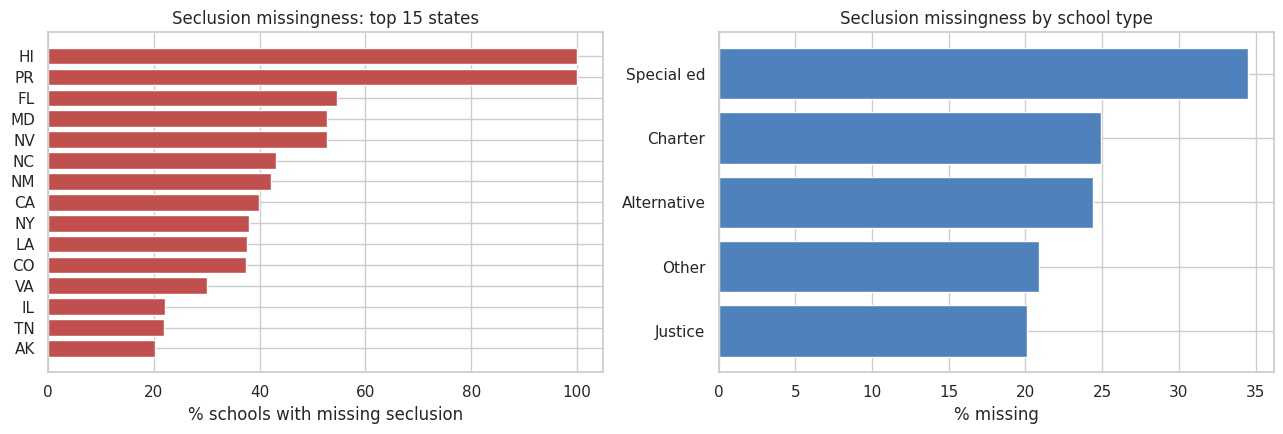

In [7]:
# How is seclusion missingness structured?
comp = ['seclusion_instances_idea','seclusion_instances_504','seclusion_instances_wodis']
n_comp_missing = full[comp].isna().sum(axis=1)
print('Number of missing seclusion components per school:'); print(n_comp_missing.value_counts().sort_index().to_string())
part = full[full.seclusion_instances.isna() & (full[comp].fillna(0).sum(axis=1) > 0)]
print(f'\nSchools with total missing but >=1 observed component > 0 (lower bound is known): {len(part)}')
print(f'Schools with total missing, 1-2 components missing, all observed components == 0: {int(((n_comp_missing.between(1,2)) & (full[comp].fillna(0).sum(axis=1)==0)).sum())}')

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
st = full.groupby('lea_state').flag_missing_seclusion.agg(['mean','sum']).sort_values('mean', ascending=False).head(15)
ax[0].barh(st.index[::-1], st['mean'][::-1]*100, color='#c0504d'); ax[0].set_xlabel('% schools with missing seclusion'); ax[0].set_title('Seclusion missingness: top 15 states')
tmp = full.assign(type=np.select([full.sch_status_sped.eq('Yes'), full.jj.eq('Yes'), full.sch_status_alt.eq('Yes'), full.sch_status_charter.eq('Yes')], ['Special ed','Justice','Alternative','Charter'], 'Other'))
t = tmp.groupby('type').flag_missing_seclusion.mean().sort_values()*100
ax[1].barh(t.index, t.values, color='#4f81bd'); ax[1].set_xlabel('% missing'); ax[1].set_title('Seclusion missingness by school type'); plt.tight_layout()

In [8]:
# Does dropping missing rows bias the analysis file? (full-file profile of missing vs non-missing)
prof = full.assign(any_flag=full.flag_missing_seclusion).groupby('any_flag').agg(
    n=('combokey','size'), median_enr=('enrollment_total','median'), mean_pct_idea=('pct_idea','mean'),
    pct_sped=('sch_status_sped', lambda s:(s=='Yes').mean()*100), pct_charter=('sch_status_charter', lambda s:(s=='Yes').mean()*100),
    pct_alt=('sch_status_alt', lambda s:(s=='Yes').mean()*100), pct_jj=('jj', lambda s:(s=='Yes').mean()*100))
prof

,n,median_enr,mean_pct_idea,pct_sped,pct_charter,pct_alt,pct_jj
any_flag,,,,,,,
False,76546,408.000,15.995,1.621,7.460,2.822,0.607
True,21029,431.000,18.488,3.105,9.240,3.267,0.542


In [9]:
# 2020-21-specific: what is behind the missing outcome? Reserved codes: -11 data-quality suppression, -13 virtual-only skip, -9 skip, -5 missing
rs = raw.seclusion_reason.fillna('valid')
print('Outcome status (all schools):'); print(pd.DataFrame({'schools': rs.value_counts(), 'share_%': rs.value_counts(normalize=True)*100}).round(2).to_string())
print('\nReserved code on the outcome:', raw.seclusion_reason_code.value_counts(dropna=False).sort_index().to_dict())
x = raw.assign(mode=raw.covid_instruction_type.fillna('not reported'), status=rs)
print('\nOutcome status by COVID instruction mode (row %):'); print((pd.crosstab(x['mode'], x.status, normalize='index')*100).round(1).to_string())
sd = raw.assign(dq=raw.seclusion_reason.eq('suppressed')).groupby('LEA_STATE').agg(schools=('dq','size'), dq_share=('dq','mean'), dq_schools=('dq','sum')).sort_values('dq_share', ascending=False)
print('\nData-quality suppression (-11) by state, top 12:'); print((sd.head(12)*[1,100,1]).round(1).to_string())
print(f"States with >50% of schools suppressed: {int((sd.dq_share>.5).sum())} | >20%: {int((sd.dq_share>.2).sum())} | the 8 biggest states account for {sd.dq_schools.nlargest(8).sum()/sd.dq_schools.sum():.0%} of all suppressed schools")
sup = raw.seclusion_reason.eq('suppressed'); ok = raw.seclusion_reason.isna()
print(f"\nSuppressed vs valid: median enrollment {raw.loc[sup,'enrollment'].median():.0f} vs {raw.loc[ok,'enrollment'].median():.0f}; special-ed {raw.loc[sup,'flag_sped'].mean():.1%} vs {raw.loc[ok,'flag_sped'].mean():.1%}; charter {raw.loc[sup,'flag_charter'].mean():.1%} vs {raw.loc[ok,'flag_charter'].mean():.1%}")

Outcome status (all schools):
                  schools  share_%
seclusion_reason                  
valid               76546   78.450
suppressed          14166   14.520
structural_skip      6575    6.740
missing               288    0.300

Reserved code on the outcome: {-13.0: 4700, -11.0: 14166, -9.0: 1875, -5.0: 288, nan: 76546}

Outcome status by COVID instruction mode (row %):
status                                  missing  structural_skip  suppressed  valid
mode                                                                               
hybrid                                    0.300            1.700      16.100 81.900
in_person_only_with_safety_precautions    0.500            7.000       2.800 89.700
no_effect_from_pandemic                   1.400            4.400       2.800 91.400
not reported                              0.000            6.900      18.200 74.900
virtual_only                              0.000           90.700       2.700  6.600

Data-quality suppression (

## 3. Distribution of seclusion instances and rates (checklist 3)
`seclusion_rate` = instances per 100 enrolled students (instances are **events**, not students, so it can exceed 100).

In [10]:
df = ana.copy()
df['any_secl'] = (df.seclusion_instances > 0).astype(int)
x = df.seclusion_instances; r = df.seclusion_rate
print(f'Schools in analysis file: {len(df):,}')
print(f'Zero seclusion: {(x==0).mean():.2%} | any seclusion: {(x>0).mean():.2%} ({(x>0).sum():,} schools)')
print(f'Total instances: {x.sum():,.0f}; mean {x.mean():.3f}; skew {x.skew():.1f}; kurtosis {x.kurt():.0f}')
print('\nInstance quantiles (all schools):', x.quantile([.5,.9,.95,.975,.99,.999]).round(1).to_dict())
pos = df[df.any_secl==1]
print('\nAmong schools with >=1 instance:'); print(pos.seclusion_instances.describe(percentiles=[.25,.5,.75,.9,.95,.99]).round(2).to_string())
print('\nRate (per 100 students) among positives:'); print(pos.seclusion_rate.describe(percentiles=[.25,.5,.75,.9,.95,.99]).round(2).to_string())
srt = x.sort_values(ascending=False).cumsum()/x.sum()
for k in (10, 50, 100, 500, 1000): print(f'Top {k:>4} schools hold {srt.iloc[k-1]:.1%} of all instances')
print(f'Schools with rate > 100 per 100 students: {(r>100).sum()}  | rate > 25: {(r>25).sum()}')

Schools in analysis file: 76,082
Zero seclusion: 94.03% | any seclusion: 5.97% (4,542 schools)
Total instances: 60,198; mean 0.791; skew 73.9; kurtosis 9891

Instance quantiles (all schools): {0.5: 0.0, 0.9: 0.0, 0.95: 1.0, 0.975: 5.0, 0.99: 17.0, 0.999: 114.0}

Among schools with >=1 instance:
count   4,542.000
mean       13.250
std        41.250
min         1.000
25%         1.000
50%         4.000
75%        10.000
90%        31.000
95%        52.950
99%       149.000
max     1,714.000

Rate (per 100 students) among positives:
count   4,542.000
mean       10.020
std        71.750
min         0.020
25%         0.340
50%         0.950
75%         3.170
90%        10.890
95%        23.890
99%       191.640
max     2,950.000
Top   10 schools hold 9.8% of all instances
Top   50 schools hold 22.5% of all instances
Top  100 schools hold 32.1% of all instances
Top  500 schools hold 64.0% of all instances
Top 1000 schools hold 79.5% of all instances
Schools with rate > 100 per 100 students: 

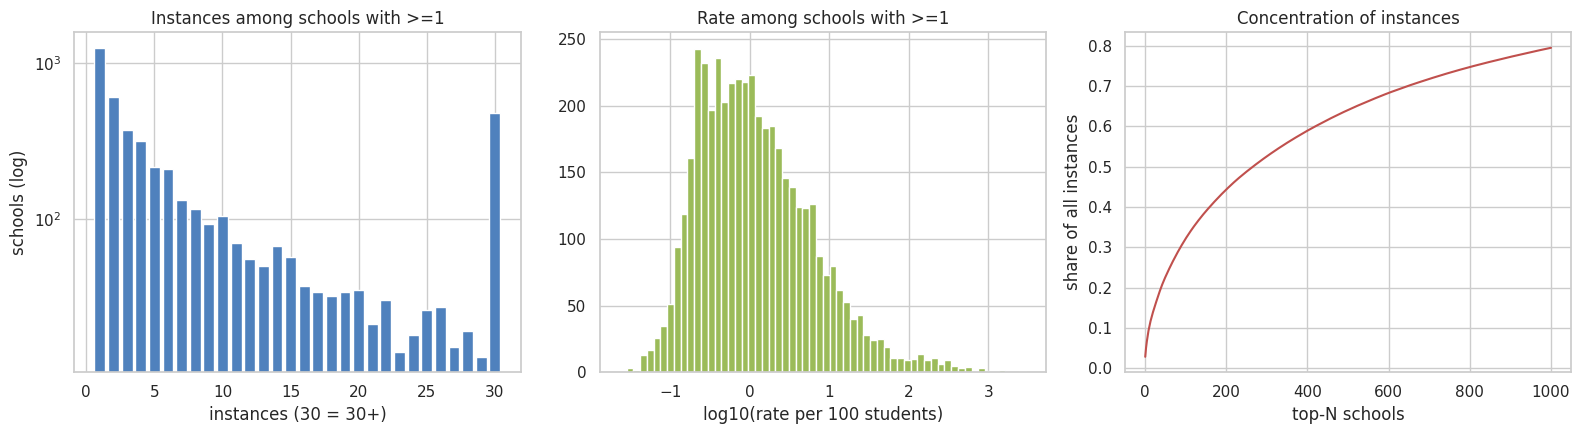

In [11]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4.5))
vc = pos.seclusion_instances.clip(upper=30).value_counts().sort_index()
ax[0].bar(vc.index.astype(int), vc.values, color='#4f81bd'); ax[0].set_yscale('log'); ax[0].set_xlabel('instances (30 = 30+)'); ax[0].set_ylabel('schools (log)'); ax[0].set_title('Instances among schools with >=1')
ax[1].hist(np.log10(pos.seclusion_rate), bins=60, color='#9bbb59'); ax[1].set_xlabel('log10(rate per 100 students)'); ax[1].set_title('Rate among schools with >=1')
ax[2].plot(np.arange(1, 1001), srt.values[:1000], color='#c0504d'); ax[2].set_xlabel('top-N schools'); ax[2].set_ylabel('share of all instances'); ax[2].set_title('Concentration of instances'); plt.tight_layout()

In [12]:
cols = ['sch_name','lea_name','lea_state','enrollment_total','seclusion_instances','seclusion_rate','sch_status_sped','sch_status_alt','jj']
print('Top 12 by instances'); display_top = df.nlargest(12, 'seclusion_instances')[cols]; print(display_top.to_string(index=False))
print('\nTop 12 by rate'); print(df.nlargest(12, 'seclusion_rate')[cols].to_string(index=False))

Top 12 by instances
                            sch_name                                lea_name lea_state  enrollment_total  seclusion_instances  seclusion_rate sch_status_sped sch_status_alt  jj
            West Kearney High School                West Kearney High School        NE           109.000            1,714.000       1,572.477              No             No Yes
     Seiter Education Service Center                       Montcalm Area Isd        MI            83.000              734.000         884.337             Yes             No  No
                 River Street School        Capitol Region Education Council        CT           194.000              610.000         314.433             Yes             No  No
      Mike Clemens Center Adapt Lrng                        Ft. Zumwalt R-Ii        MO            18.000              531.000       2,950.000             Yes             No  No
            Community Youth Services              Richmond Community Schools        IN         

## 4. Share reporting any seclusion and a threshold for "elevated" (checklist 4)

In [13]:
tiers = pd.DataFrame({'schools': [(x>=k).sum() for k in (1,2,3,5,10,20,50)], 'share_of_schools': [(x>=k).mean() for k in (1,2,3,5,10,20,50)],
                     'share_of_instances': [x[x>=k].sum()/x.sum() for k in (1,2,3,5,10,20,50)]}, index=[f'>= {k} instances' for k in (1,2,3,5,10,20,50)])
print(tiers.to_string())
# rate-based alternatives restricted to enrollment >= 30 (see section 9)
big = df[df.enrollment_total >= 30]
print('\nRate thresholds (enrollment >= 30): p90/p95/p99 among positives =', big[big.any_secl==1].seclusion_rate.quantile([.9,.95,.99]).round(2).to_dict())
print('Schools with rate >= 1 per 100 :', (big.seclusion_rate>=1).sum(), f'({(big.seclusion_rate>=1).mean():.2%})')
print('Schools with rate >= 5 per 100 :', (big.seclusion_rate>=5).sum(), f'({(big.seclusion_rate>=5).mean():.2%})')
print('Schools with >=5 instances AND rate >= 1 : ', ((big.seclusion_instances>=5)&(big.seclusion_rate>=1)).sum(), f'({((big.seclusion_instances>=5)&(big.seclusion_rate>=1)).mean():.2%})')

                 schools  share_of_schools  share_of_instances
>= 1 instances      4542             0.060               1.000
>= 2 instances      3290             0.043               0.979
>= 3 instances      2682             0.035               0.959
>= 5 instances      1996             0.026               0.920
>= 10 instances     1233             0.016               0.836
>= 20 instances      693             0.009               0.715
>= 50 instances      246             0.003               0.484

Rate thresholds (enrollment >= 30): p90/p95/p99 among positives = {0.9: 8.87, 0.95: 17.88, 0.99: 109.46}
Schools with rate >= 1 per 100 : 2112 (2.88%)
Schools with rate >= 5 per 100 : 751 (1.03%)
Schools with >=5 instances AND rate >= 1 :  1757 (2.40%)

In [14]:
# Is 'any' a one-off or a pattern? How does the share of schools with 1,2,3+ instances look within the positive group?
print((pos.seclusion_instances.clip(upper=10)).value_counts(normalize=True).sort_index().round(3).to_string())
# Which component drives it?
comp_tot = ana[['seclusion_instances_idea','seclusion_instances_504','seclusion_instances_wodis']].sum()
print('\nInstance totals by student group:'); print((comp_tot/comp_tot.sum()).round(4).to_string())
print('\nSchools with any instance, by group:', {c.replace('seclusion_instances_',''): int((ana[c]>0).sum()) for c in comp_tot.index})

seclusion_instances
1.000    0.276
2.000    0.134
3.000    0.082
4.000    0.069
5.000    0.047
6.000    0.046
7.000    0.029
8.000    0.025
9.000    0.020
10.000   0.271

Instance totals by student group:
seclusion_instances_idea    0.829
seclusion_instances_504     0.007
seclusion_instances_wodis   0.164

Schools with any instance, by group: {'idea': 4024, '504': 143, 'wodis': 1322}

## 5. School types and grade levels (checklist 5)

In [15]:
df['type_sped']=df.sch_status_sped.eq('Yes'); df['type_alt']=df.sch_status_alt.eq('Yes'); df['type_charter']=df.sch_status_charter.eq('Yes')
df['type_magnet']=df.sch_status_magnet.eq('Yes'); df['type_jj']=df.jj.eq('Yes')
df['type_virtual_name'] = df.sch_name.str.contains(r'virtual|online|cyber|e-?learning|distance', case=False, na=False)   # PROXY: no virtual indicator exists in 2015-16
df['regular'] = ~(df.type_sped | df.type_alt | df.type_jj)
df['enr_ge30'] = df.enrollment_total >= 30

def summ(d, by):
    g = d.groupby(by)
    out = pd.DataFrame({'schools': g.size(), 'pct_any_secl': g.any_secl.mean()*100,
        'mean_instances': g.seclusion_instances.mean(),
        'median_rate_if_any': g.apply(lambda s: s.loc[s.any_secl==1,'seclusion_rate'].median()),
        'share_of_all_instances_%': g.seclusion_instances.sum()/d.seclusion_instances.sum()*100})
    return out

rows = []
for col, lab in [('type_sped','Special education'),('type_alt','Alternative'),('type_charter','Charter'),('type_magnet','Magnet'),('type_jj','Justice facility'),('type_virtual_name','Virtual (name proxy)')]:
    t_ = summ(df, col); t_.index = t_.index.map({True: 'Yes', False: 'No'})
    rows += [t_.loc[['Yes']].rename(index={'Yes': lab}), t_.loc[['No']].rename(index={'No': lab + ' = No'})]
type_tbl = pd.concat(rows); type_tbl

,schools,pct_any_secl,mean_instances,median_rate_if_any,share_of_all_instances_%
Special education,1235,20.486,8.708,16.842,17.864
Special education = No,74847,5.730,0.661,0.858,82.136
Alternative,2159,1.667,0.469,14.573,1.681
Alternative = No,73923,6.096,0.801,0.941,98.319
Charter,5691,1.546,0.148,1.303,1.402
Charter = No,70391,6.328,0.843,0.950,98.598
Magnet,2062,4.656,0.376,0.597,1.289
Magnet = No,74020,6.006,0.803,0.958,98.711
Justice facility,465,9.677,7.447,143.590,5.753
Justice facility = No,75617,5.947,0.750,0.939,94.247


,schools,pct_any_secl,mean_instances,median_rate_if_any,share_of_all_instances_%
grade_band,,,,,
elementary,29101,8.749,1.065,1.015,51.493
high,13554,2.295,0.340,0.353,7.663
middle,10482,4.131,0.283,0.418,4.920
other,152,7.895,4.546,4.155,1.148
span,22793,5.440,0.918,1.323,34.775


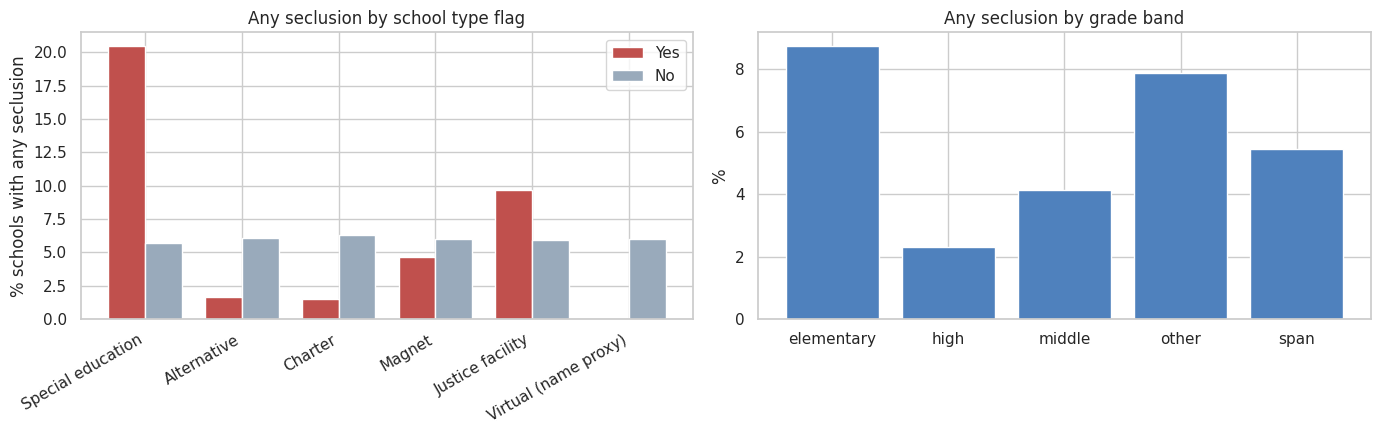

In [16]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
labs = ['Special education','Alternative','Charter','Magnet','Justice facility','Virtual (name proxy)']; cols = ['type_sped','type_alt','type_charter','type_magnet','type_jj','type_virtual_name']
yes = [df.loc[df[c],'any_secl'].mean()*100 for c in cols]; no = [df.loc[~df[c],'any_secl'].mean()*100 for c in cols]
w=.38; i=np.arange(len(cols)); ax[0].bar(i-w/2, yes, w, label='Yes', color='#c0504d'); ax[0].bar(i+w/2, no, w, label='No', color='#9ab'); ax[0].set_xticks(i); ax[0].set_xticklabels(labs, rotation=30, ha='right'); ax[0].set_ylabel('% schools with any seclusion'); ax[0].legend(); ax[0].set_title('Any seclusion by school type flag')
gb = summ(df, 'grade_band'); ax[1].bar(gb.index, gb.pct_any_secl, color='#4f81bd'); ax[1].set_title('Any seclusion by grade band'); ax[1].set_ylabel('%')
plt.tight_layout(); gb

In [17]:
# Grade band within regular schools only (removes the special-ed / alternative / justice effect) and type x grade
print('Regular schools (not sped / alt / justice) by grade band'); print(summ(df[df.regular], 'grade_band').round(2).to_string())
print(f'\nShare of the {len(pos):,} schools with any seclusion that are...')
pos = df[df.any_secl==1]
print({k: f'{pos[k].mean():.1%} (vs {df[k].mean():.1%} of all schools)' for k in ['type_sped','type_alt','type_charter','type_magnet','type_jj','type_virtual_name']})
print('\nRegular school share of positives:', f'{pos.regular.mean():.1%}')

Regular schools (not sped / alt / justice) by grade band
            schools  pct_any_secl  mean_instances  median_rate_if_any  share_of_all_instances_%
grade_band                                                                                     
elementary    28966         8.690           1.040               1.000                    65.730
high          12127         2.280           0.160               0.270                     4.220
middle        10406         4.110           0.270               0.400                     6.130
other            37         0.000           0.000                 NaN                     0.000
span          20895         4.800           0.520               0.930                    23.920

Share of the 4,542 schools with any seclusion that are...
{'type_sped': '5.6% (vs 1.6% of all schools)', 'type_alt': '0.8% (vs 2.8% of all schools)', 'type_charter': '1.9% (vs 7.5% of all schools)', 'type_magnet': '2.1% (vs 2.7% of all schools)', 'type_jj': '1.0% (vs 0.

## 5b. COVID instruction mode (2020-21 only)
The 2020-21 file adds a self-reported instruction mode (`SCH_DIND_INSTRUCTIONTYPE`): in-person with safety precautions, virtual only, hybrid, or no effect from the pandemic. Virtual-only schools skipped the seclusion module (-13), so their valid-outcome sample is tiny and selective.

                                        schools_all  pct_outcome_missing  schools_with_outcome  pct_any_secl  mean_instances  median_rate_if_any
covid_mode                                                                                                                                      
hybrid                                        85657               18.060                 69789         6.090           0.750               0.900
in_person_only_with_safety_precautions         5392               10.290                  4778         5.760           1.220               2.380
no_effect_from_pandemic                        1090                8.620                   994         1.210           1.820               2.040
not reported                                    247               25.100                   181         2.210           0.030               0.230
virtual_only                                   5189               93.410                   340         0.880           0.070      

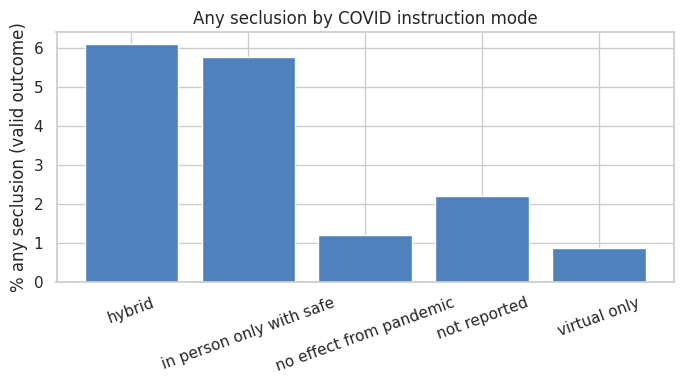

In [18]:
df['covid_mode'] = df.covid_instruction_type.fillna('not reported')
mode_tbl = summ(df, 'covid_mode')
fm = full.assign(covid_mode=full.covid_instruction_type.fillna('not reported')).groupby('covid_mode').agg(schools_all=('combokey','size'), pct_outcome_missing=('flag_missing_seclusion', lambda s: s.mean()*100))
mode_all = fm.join(mode_tbl[['schools','pct_any_secl','mean_instances','median_rate_if_any']]).rename(columns={'schools':'schools_with_outcome'}); print(mode_all.round(2).to_string())
vt = df.assign(vt=df.covid_virtual_type.fillna('none / skip')).groupby('vt').agg(schools=('combokey','size'), pct_any_secl=('any_secl', lambda s: s.mean()*100)); print('\nBy virtual instruction type (valid outcome):'); print(vt.round(2).to_string())
# Instruction mode vs seclusion after adjusting for state, size, and school type (regular schools, enr>=30)
from sklearn.linear_model import LogisticRegression
m_ = df[df.regular & df.enr_ge30 & ~df.flag_fte_outlier].copy()
X = pd.concat([pd.get_dummies(m_.covid_mode, dtype=float).drop(columns='hybrid'), pd.get_dummies(m_.lea_state, prefix='st', dtype=float), pd.DataFrame({'log_enr': np.log(m_.enrollment_total)}, index=m_.index)], axis=1)
lr = LogisticRegression(max_iter=4000, C=10).fit(X, m_.any_secl)
modes_ = [c for c in X.columns if c in set(m_.covid_mode)]
print('\nOdds ratios vs hybrid, adjusted for state and log enrollment (regular schools, enr>=30; n per mode: ' + str(m_.covid_mode.value_counts().to_dict()) + ')')
print(np.exp(pd.Series(lr.coef_[0], index=X.columns)[modes_]).round(2).to_string())
fig, ax = plt.subplots(figsize=(7, 4)); mm = mode_all[mode_all.schools_with_outcome >= 100]; ax.bar([i.replace('_',' ')[:24] for i in mm.index], mm.pct_any_secl, color='#4f81bd'); ax.set_ylabel('% any seclusion (valid outcome)'); ax.set_title('Any seclusion by COVID instruction mode'); ax.tick_params(axis='x', rotation=20); plt.tight_layout()

## 6. States and districts (checklist 6)

In [19]:
stt = df.groupby('lea_state').agg(schools=('combokey','size'), pct_any=('any_secl', lambda s: s.mean()*100), instances=('seclusion_instances','sum'), enroll=('enrollment_total','sum'))
stt['instances_per_1000_students'] = stt.instances/stt.enroll*1000
stt['pct_missing_in_full_file'] = full.groupby('lea_state').flag_missing_seclusion.mean()*100
stt = stt.sort_values('pct_any', ascending=False)
print('Top 10 / bottom 12 states by % schools with any seclusion'); print(pd.concat([stt.head(10), stt.tail(12)]).round(2).to_string())
print('\nStates with 0 schools reporting any seclusion:', stt.index[stt.pct_any==0].tolist())
print('Median state % any:', round(stt.pct_any.median(),2), '| IQR', stt.pct_any.quantile([.25,.75]).round(2).tolist())

Top 10 / bottom 12 states by % schools with any seclusion
           schools  pct_any  instances        enroll  instances_per_1000_students  pct_missing_in_full_file
lea_state                                                                                                  
IA            1248   29.250  5,548.000   485,557.000                       11.430                     4.520
WI            1784   27.750  3,426.000   681,583.000                        5.030                    18.850
CT            1061   25.920  4,082.000   468,118.000                        8.720                     9.780
ME             510   22.940  1,388.000   154,512.000                        8.980                    10.100
NE             876   17.920  6,153.000   267,566.000                       23.000                    16.210
IN            1676   16.290  4,497.000   946,557.000                        4.750                     9.690
KS            1314   16.130  3,218.000   467,364.000                        6.

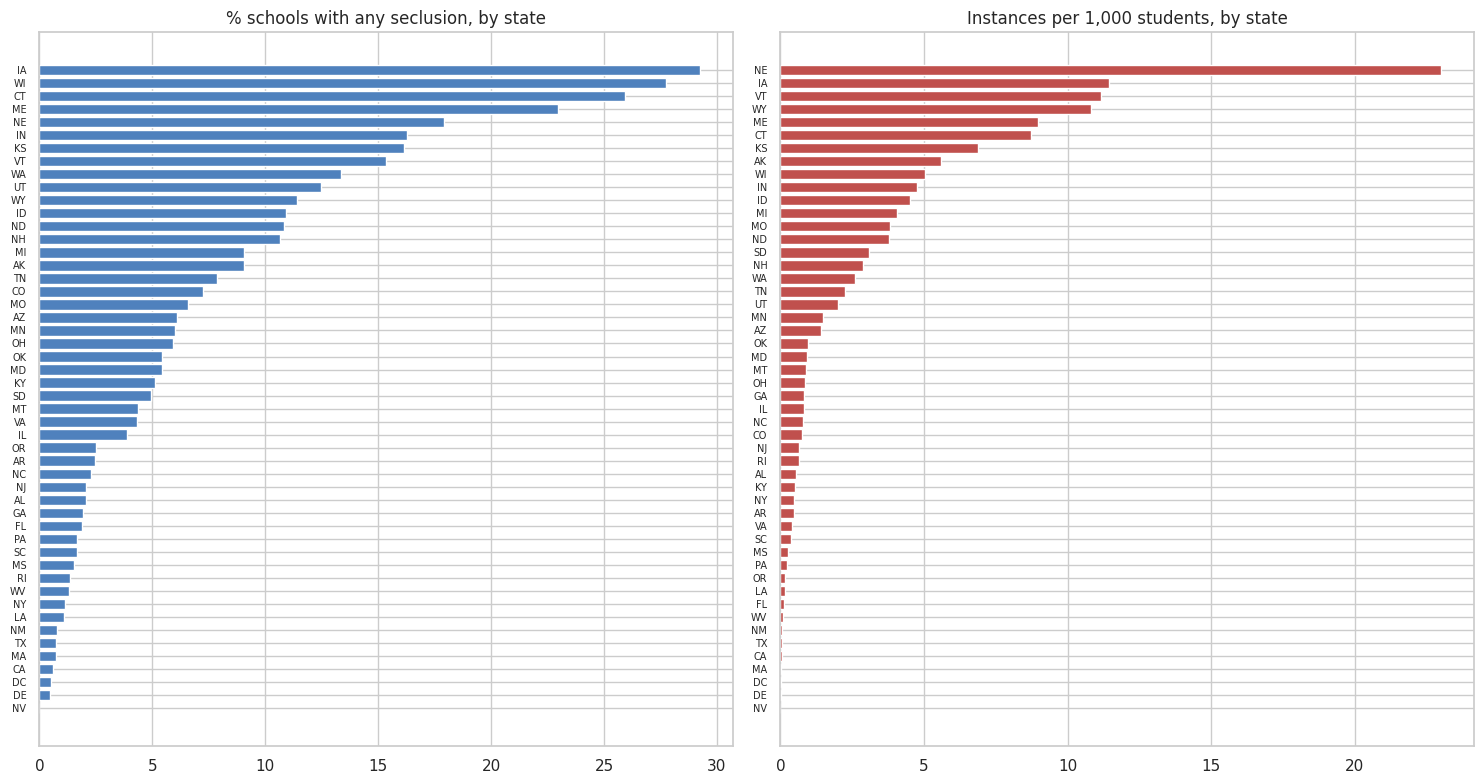

In [20]:
fig, ax = plt.subplots(1, 2, figsize=(15, 8))
s = stt.sort_values('pct_any'); ax[0].barh(s.index, s.pct_any, color='#4f81bd'); ax[0].set_title('% schools with any seclusion, by state'); ax[0].tick_params(axis='y', labelsize=7)
s = stt.sort_values('instances_per_1000_students'); ax[1].barh(s.index, s.instances_per_1000_students, color='#c0504d'); ax[1].set_title('Instances per 1,000 students, by state'); ax[1].tick_params(axis='y', labelsize=7); plt.tight_layout()

Districts: 16,591; with >=1 school reporting any seclusion: 1,881 (11.3%)
Top  10 districts = 18.0% of instances
Top  50 districts = 37.9% of instances
Top 100 districts = 52.8% of instances
Top 500 districts = 86.9% of instances
Districts that account for 50% of instances: 89; for 80%: 355
                                            lea_name state  schools  schools_any  instances     enroll  share_instances_%  cum_share_%
leaid                                                                                                                                 
3172840                       Lincoln Public Schools    NE       69           49  2,407.000 41,173.000              4.000        4.000
3100046                     West Kearney High School    NE        1            1  1,714.000    109.000              2.800        6.800
2908370                             Ft. Zumwalt R-Ii    MO       26           15  1,339.000 17,127.000              2.200        9.100
1300026               Department 

(0.0, 10.0)

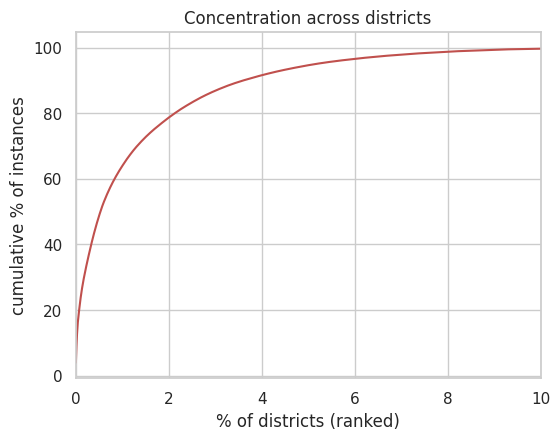

In [21]:
dist = df.groupby(['leaid']).agg(lea_name=('lea_name','first'), state=('lea_state','first'), schools=('combokey','size'), schools_any=('any_secl','sum'),
                                  instances=('seclusion_instances','sum'), enroll=('enrollment_total','sum')).sort_values('instances', ascending=False)
dist['share_instances_%'] = dist.instances/dist.instances.sum()*100; dist['cum_share_%'] = dist['share_instances_%'].cumsum()
print(f'Districts: {len(dist):,}; with >=1 school reporting any seclusion: {(dist.schools_any>0).sum():,} ({(dist.schools_any>0).mean():.1%})')
for k in (10, 50, 100, 500): print(f'Top {k:>3} districts = {dist.instances.iloc[:k].sum()/dist.instances.sum():.1%} of instances')
print(f'Districts that account for 50% of instances: {(dist["cum_share_%"]<50).sum()+1}; for 80%: {(dist["cum_share_%"]<80).sum()+1}')
print(dist.head(15).round(1).to_string())
fig, ax = plt.subplots(figsize=(6,4.5)); d2 = dist[dist.instances>0]; ax.plot(np.arange(1,len(d2)+1)/len(dist)*100, d2['cum_share_%'].values, color='#c0504d'); ax.set_xlabel('% of districts (ranked)'); ax.set_ylabel('cumulative % of instances'); ax.set_title('Concentration across districts'); ax.set_xlim(0,10)

In [22]:
# Within-state vs between-state: how much of 'any seclusion' is explained by state alone, and by district?
from sklearn.metrics import roc_auc_score
st_mean = df.groupby('lea_state').any_secl.transform('mean'); print('AUC of state-mean alone    :', round(roc_auc_score(df.any_secl, st_mean),3))
lea_mean = df.groupby('leaid').any_secl.transform('mean'); print('AUC of district-mean (in-sample, optimistic, leaky):', round(roc_auc_score(df.any_secl, lea_mean),3))
print('Positives sitting in districts where >=50% of schools are positive:', f"{pos.leaid.map(df.groupby('leaid').any_secl.mean()).ge(.5).mean():.1%}")
print('Single-school districts among positives:', f"{(pos.leaid.map(df.groupby('leaid').size())==1).mean():.1%}")

AUC of state-mean alone    : 0.798
AUC of district-mean (in-sample, optimistic, leaky): 0.963
Positives sitting in districts where >=50% of schools are positive: 41.5%
Single-school districts among positives: 3.9%

## 7. Staffing and seclusion (checklist 7)
Per-100 ratios are rebuilt from the FTE counts, with rows flagged `flag_fte_outlier` excluded and ratios capped at the 99.5th percentile, because several FTE values are impossible (e.g. 19,048.6 psychologists at one school — see Data Issues).

In [23]:
st = df[~df.flag_fte_outlier & df.enrollment_total.ge(30)].copy()
for c in ['counselors','psych','social','nurses','leo','guards','teachers']:
    st[f'{c}_p100'] = st[f'fte_{c}']/st.enrollment_total*100
    st[f'{c}_p100'] = st[f'{c}_p100'].clip(upper=st[f'{c}_p100'].quantile(.995))
staff = ['counselors','psych','social','nurses','leo','guards']
staff_reg = list(staff)   # fte_leo is only 5.7% missing in 2020-21
print('Schools with usable fte_leo among enr>=30:', int(st.fte_leo.notna().sum()), 'of', len(st))
out = []
for c in staff:
    for lab, d in [('All (enr>=30)', st), ('Regular schools', st[st.regular])]:
        d = d.dropna(subset=[f'fte_{c}'])
        has = d[f'fte_{c}']>0
        pos_p = d.loc[has, f'{c}_p100']; terc = pd.qcut(pos_p, 3, labels=['low','mid','high'], duplicates='drop')
        r = {'staff': c, 'sample': lab, 'share_with_any_FTE_%': has.mean()*100, 'any_secl_%_none': d.loc[~has,'any_secl'].mean()*100}
        for t in ['low','mid','high']: r[f'any_secl_%_{t}'] = d.loc[pos_p.index[terc==t],'any_secl'].mean()*100
        out.append(r)
staff_tbl = pd.DataFrame(out).set_index(['staff','sample']); staff_tbl.round(2)

Schools with usable fte_leo among enr>=30: 70551 of 73130

share_with_any_FTE_%  any_secl_%_none  any_secl_%_low  any_secl_%_mid  any_secl_%_high
staff      sample                                                                                                 
counselors All (enr>=30)                  79.100            7.010           6.310           6.530            4.650
           Regular schools                79.930            6.350           6.260           6.550            4.660
psych      All (enr>=30)                  50.160            4.660           5.980           8.480            8.000
           Regular schools                50.410            4.530           5.940           8.540            7.420
social     All (enr>=30)                  36.730            5.000           6.860           8.200            8.770
           Regular schools                36.650            4.940           6.740           8.300            7.840
nurses     All (enr>=30)                  73.610            5.010           7.060           6.010            6.320
           Regular schools                74.400            4.900           7.070           5.960            5.800
leo        All (enr>=30)                  34.490            6.230           8.310           5.650            4.110
           Regular schools                34.850            6.050           8.380           5.630            3.930
guards     All (enr>=30)                  14.490            6.510           4.640           4.260            3.350
           Regular schools                14.350            6.390           4.760           4.140            2.720

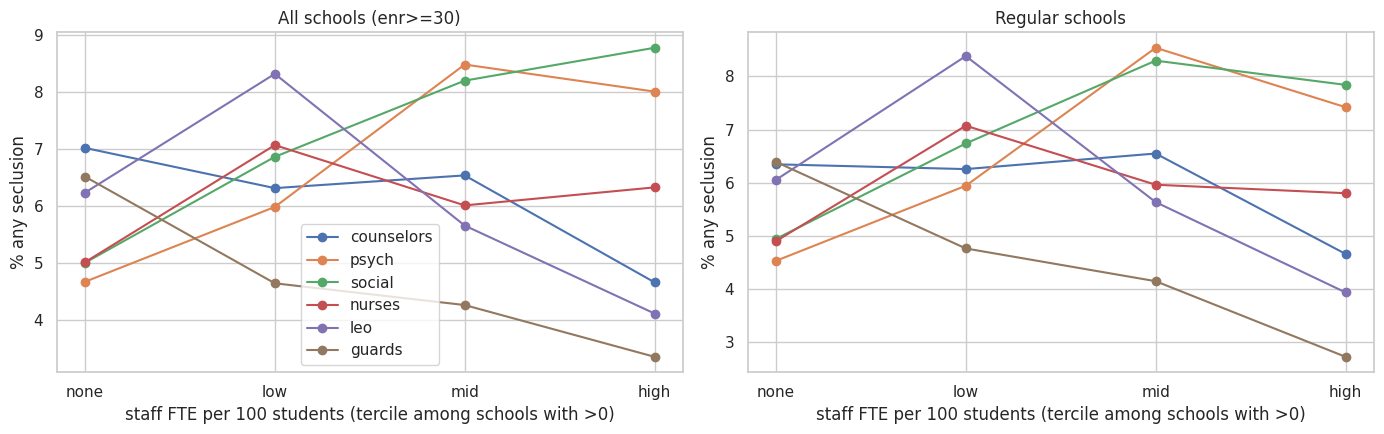

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for ax, (lab, d) in zip(axes, [('All schools (enr>=30)', st), ('Regular schools', st[st.regular])]):
    for c in staff:
        dd = d.dropna(subset=[f'fte_{c}']); has = dd[f'fte_{c}']>0; pp = dd.loc[has, f'{c}_p100']; t = pd.qcut(pp, 3, labels=['low','mid','high'], duplicates='drop')
        vals = [dd.loc[~has,'any_secl'].mean()*100] + [dd.loc[pp.index[t==k],'any_secl'].mean()*100 for k in ['low','mid','high']]
        ax.plot(['none','low','mid','high'], vals, marker='o', label=c)
    ax.set_title(lab); ax.set_ylabel('% any seclusion'); ax.set_xlabel('staff FTE per 100 students (tercile among schools with >0)')
axes[0].legend(); plt.tight_layout()

In [25]:
# Staffing relationship after controlling for size, school type, grade band and population (logistic regression, standardised)
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
X = st[st.regular].dropna(subset=['pct_idea','pct_el','pct_504']+[f'{c}_p100' for c in staff_reg]).copy()
feat = ['log_enr','pct_idea','pct_504','pct_el']+[f'{c}_p100' for c in staff_reg]
X['log_enr'] = np.log(X.enrollment_total)
Xd = pd.concat([X[feat], pd.get_dummies(X.grade_band, drop_first=True, dtype=float)], axis=1)
m = LogisticRegression(max_iter=2000, C=1.0).fit(StandardScaler().fit_transform(Xd), X.any_secl)
coef = pd.Series(m.coef_[0], index=Xd.columns).sort_values(); print('Standardised log-odds coefficients (regular schools, enr>=30):'); coef.round(3)

Standardised log-odds coefficients (regular schools, enr>=30):

,0
high,-0.515
pct_504,-0.348
span,-0.272
middle,-0.244
pct_el,-0.194
guards_p100,-0.194
leo_p100,-0.121
nurses_p100,-0.098
other,-0.055
counselors_p100,0.069


## 8. Student population and seclusion (checklist 8)

pct_idea
                size  pct_any
pct_idea_bin                 
(-0.1, 5.0]     2857    2.630
(5.0, 10.0]    12172    4.030
(10.0, 15.0]   26530    5.700
(15.0, 20.0]   18243    7.000
(20.0, 30.0]    8769    8.030
(30.0, 50.0]     949    4.430
(50.0, 100.1]    175   10.290 

pct_504
                size  pct_any
pct_504_bin                  
(-0.1, 0.5]    15521    6.890
(0.5, 2.0]     19166    7.840
(2.0, 5.0]     20760    5.470
(5.0, 10.0]    11084    3.290
(10.0, 100.1]   3164    1.390 

pct_el
                size  pct_any
pct_el_bin                   
(-0.1, 1.0]    20823    4.560
(1.0, 5.0]     20048    6.810
(5.0, 15.0]    15593    7.310
(15.0, 40.0]   10055    5.600
(40.0, 100.1]   3176    3.120 

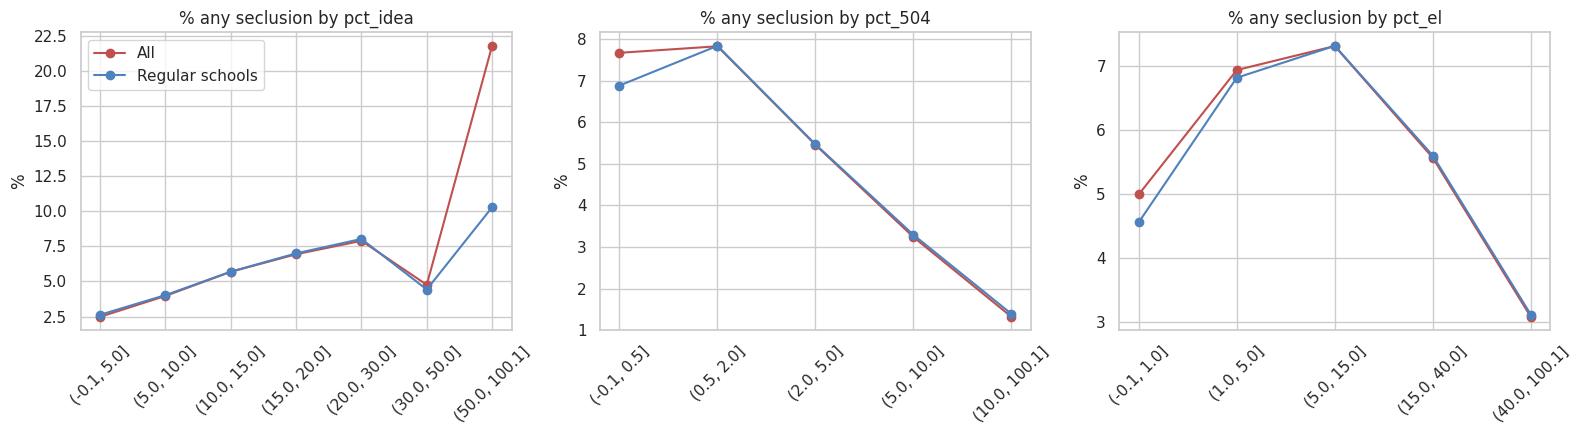

In [26]:
pp = df[df.enr_ge30 & df.pct_idea.notna() & df.pct_el.notna() & df.pct_504.notna()].copy()
bins = {'pct_idea':[-.1,5,10,15,20,30,50,100.1], 'pct_504':[-.1,.5,2,5,10,100.1], 'pct_el':[-.1,1,5,15,40,100.1]}
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5)); res = {}
for ax, (c, b) in zip(axes, bins.items()):
    pp[c+'_bin'] = pd.cut(pp[c], b)
    for lab, d, col in [('All', pp, '#c0504d'), ('Regular schools', pp[pp.regular], '#4f81bd')]:
        g = d.groupby(c+'_bin', observed=True).any_secl.agg(['mean','size']); ax.plot(g.index.astype(str), g['mean']*100, marker='o', label=lab, color=col); res[(c, lab)] = g
    ax.set_title(f'% any seclusion by {c}'); ax.tick_params(axis='x', rotation=45); ax.set_ylabel('%')
axes[0].legend(); plt.tight_layout()
for k, v in res.items():
    if k[1]=='Regular schools': print(k[0]); print((v.assign(**{'pct_any': v['mean']*100}).drop(columns='mean')).round(2).to_string(), '\n')

In [27]:
sp = pp[['any_secl','pct_idea','pct_504','pct_el','seclusion_rate','enrollment_total']].copy(); sp['log_enr']=np.log(sp.enrollment_total)
print('Spearman with any_secl (all, enr>=30):'); print(sp.corr(method='spearman')['any_secl'].drop('any_secl').round(3).to_string())
r_ = pp[pp.regular]; print('\nSpearman with any_secl (regular schools):'); print(r_[['any_secl','pct_idea','pct_504','pct_el']].corr(method='spearman')['any_secl'].drop('any_secl').round(3).to_string())
print('\nRegular schools, any_secl by whether %IDEA is above regular-school median:', r_.groupby(r_.pct_idea>r_.pct_idea.median()).any_secl.mean().mul(100).round(2).to_dict())

Spearman with any_secl (all, enr>=30):
pct_idea            0.071
pct_504            -0.077
pct_el              0.012
seclusion_rate      0.999
enrollment_total   -0.003
log_enr            -0.003

Spearman with any_secl (regular schools):
pct_idea    0.058
pct_504    -0.066
pct_el      0.020

Regular schools, any_secl by whether %IDEA is above regular-school median: {False: 4.8, True: 7.01}

## 9. Small enrollments and rate distortion (checklist 9)
A single instance in a school of 10 students is a rate of 10 per 100. Rates for tiny schools are driven by the denominator.

                  schools  pct_any  median_rate_if_any  p95_rate_if_any  pct_rate_gt_100  pct_special_ed
enrollment_total                                                                                        
1-9                   978    1.940              50.000          711.430            0.610          11.150
10-29                1886    4.030              51.690          661.250            1.540          14.370
30-99                4933    4.120               9.860          325.830            0.770           9.970
100-249             12003    5.060               1.880           29.810            0.070           2.100
250-499             27953    7.450               1.000           13.180            0.000           0.300
500-999             21917    5.840               0.540            8.080            0.000           0.090
1000+                6412    4.290               0.150            2.130            0.000           0.120

Schools under 30 students: 2,864 (3.8%); they hold 4.4

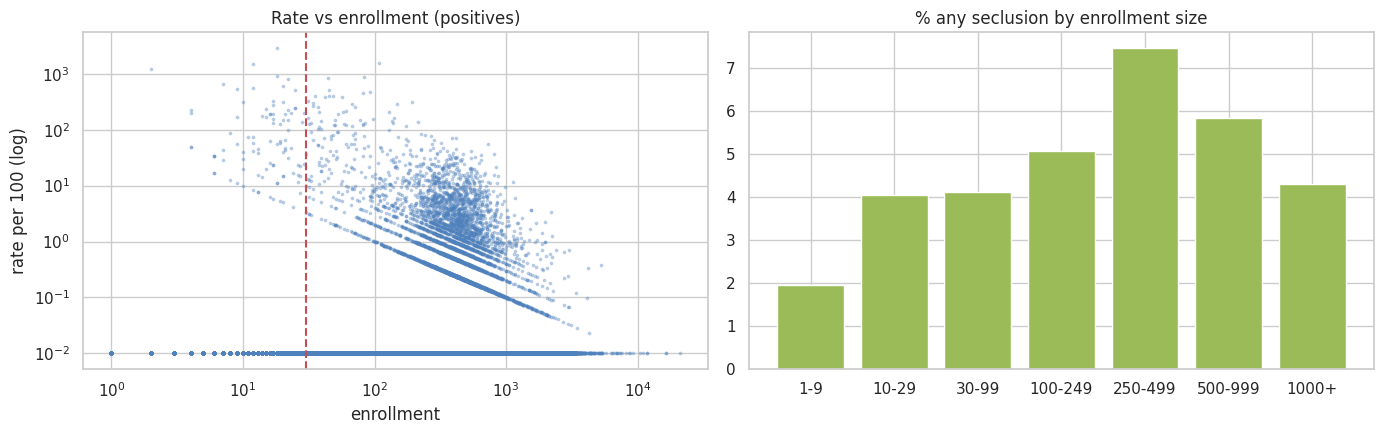

In [28]:
eb = pd.cut(df.enrollment_total, [0,9,29,99,249,499,999,1e6], labels=['1-9','10-29','30-99','100-249','250-499','500-999','1000+'])
g = df.groupby(eb, observed=True)
small = pd.DataFrame({'schools': g.size(), 'pct_any': g.any_secl.mean()*100,
    'median_rate_if_any': g.apply(lambda s: s.loc[s.any_secl==1,'seclusion_rate'].median()),
    'p95_rate_if_any': g.apply(lambda s: s.loc[s.any_secl==1,'seclusion_rate'].quantile(.95)),
    'pct_rate_gt_100': g.apply(lambda s: (s.seclusion_rate>100).mean()*100),
    'pct_special_ed': g.type_sped.mean()*100})
print(small.round(2).to_string())
print(f'\nSchools under 30 students: {(df.enrollment_total<30).sum():,} ({(df.enrollment_total<30).mean():.1%}); they hold {df.loc[df.enrollment_total<30,"seclusion_instances"].sum()/df.seclusion_instances.sum():.1%} of instances but {(df.loc[df.seclusion_rate>100].enrollment_total<30).mean():.0%} of rate>100 schools')
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
ax[0].scatter(df.enrollment_total, df.seclusion_rate.clip(lower=.01), s=3, alpha=.3, color='#4f81bd'); ax[0].set_xscale('log'); ax[0].set_yscale('log'); ax[0].set_xlabel('enrollment'); ax[0].set_ylabel('rate per 100 (log)'); ax[0].set_title('Rate vs enrollment (positives)'); ax[0].axvline(30, color='r', ls='--')
ax[1].bar(small.index.astype(str), small.pct_any, color='#9bbb59'); ax[1].set_title('% any seclusion by enrollment size'); plt.tight_layout()

In [29]:
# Candidate smoothing: empirical-Bayes-style shrinkage toward the overall rate, k = pseudo-students
m0 = df.seclusion_instances.sum()/df.enrollment_total.sum()*100
for k in (30, 100): df[f'rate_eb_k{k}'] = (df.seclusion_instances + k*m0/100)/(df.enrollment_total + k)*100
top = lambda col, n=100: set(df.nlargest(n, col).combokey)
print(f'Overall rate m0 = {m0:.2f} per 100')
for col in ['seclusion_rate','rate_eb_k30','rate_eb_k100']:
    t = df.nlargest(100, col); print(f'{col:>14}: median enrollment of top-100 = {t.enrollment_total.median():.0f}; share with enrollment<30 = {(t.enrollment_total<30).mean():.0%}; share sped = {t.type_sped.mean():.0%}')
print('\nOverlap of top-100 raw vs EB(k=30):', len(top('seclusion_rate') & top('rate_eb_k30')), '| min-enrollment-30 raw top-100 vs EB(k=30):', len(set(df[df.enr_ge30].nlargest(100,'seclusion_rate').combokey) & top('rate_eb_k30')))

Overall rate m0 = 0.16 per 100
seclusion_rate: median enrollment of top-100 = 38; share with enrollment<30 = 39%; share sped = 51%
   rate_eb_k30: median enrollment of top-100 = 46; share with enrollment<30 = 32%; share sped = 52%
  rate_eb_k100: median enrollment of top-100 = 67; share with enrollment<30 = 21%; share sped = 46%

Overlap of top-100 raw vs EB(k=30): 92 | min-enrollment-30 raw top-100 vs EB(k=30): 68

## 10. COVID check: 2020-21 vs 2017-18 and 2021-22 (checklist 10)
2020-21 is used here only as a sensitivity check on the other years. The outcome is available for only 78% of schools and the missing 22% are concentrated in a few states, so naive prevalence comparisons are confounded by *who reported*. Four views are used: (A) naive prevalence, (B) why naive is biased (state selection), (C) post-stratified to the 2020-21 roster, and (D) a balanced panel of the same schools in all three waves, which removes school-composition effects.

(A) Naive prevalence (all analysis-ready schools in each wave)
         schools_with_outcome  pct_any_seclusion  mean_instances  states
2017-18            91,013.000              6.560           1.560  51.000
2020-21            76,082.000              5.970           0.790  50.000
2021-22            93,094.000              7.090           1.160  52.000

(B) State-level correlation between share of schools with a valid 2020-21 outcome and the state's 2017-18 prevalence: Spearman 0.32
    Low-validity states (<60% valid) average 2017-18 prevalence 2.7% vs 9.5% for states with >=90% valid
    States below 60% valid: {'CA': 60.0, 'FL': 45.0, 'HI': 0.0, 'MD': 47.0, 'NC': 57.0, 'NM': 58.0, 'NV': 47.0, 'PR': 0.0}

(C) Prevalence post-stratified to the 2020-21 roster state mix (50 states): 2017-18 6.59%, 2020-21 5.55%, 2021-22 7.23%
    Only states with >=90% valid outcomes in 2020-21 (20 states): 2017-18 9.30%, 2020-21 8.09%, 2021-22 10.13%

(D) Balanced panel (valid in all three waves): 67,7

,schools,any_2017_18,any_2020_21,any_2021_22,change_2018_to_2021_pts
covid_mode,,,,,
hybrid,62726,7.920,6.230,8.500,-1.690
in_person_only_with_safety_precautions,4157,5.770,5.630,5.680,-0.140
no_effect_from_pandemic,464,3.230,2.160,3.230,-1.080
not reported,161,1.860,2.480,5.590,0.620
virtual_only,267,1.500,0.370,4.120,-1.120


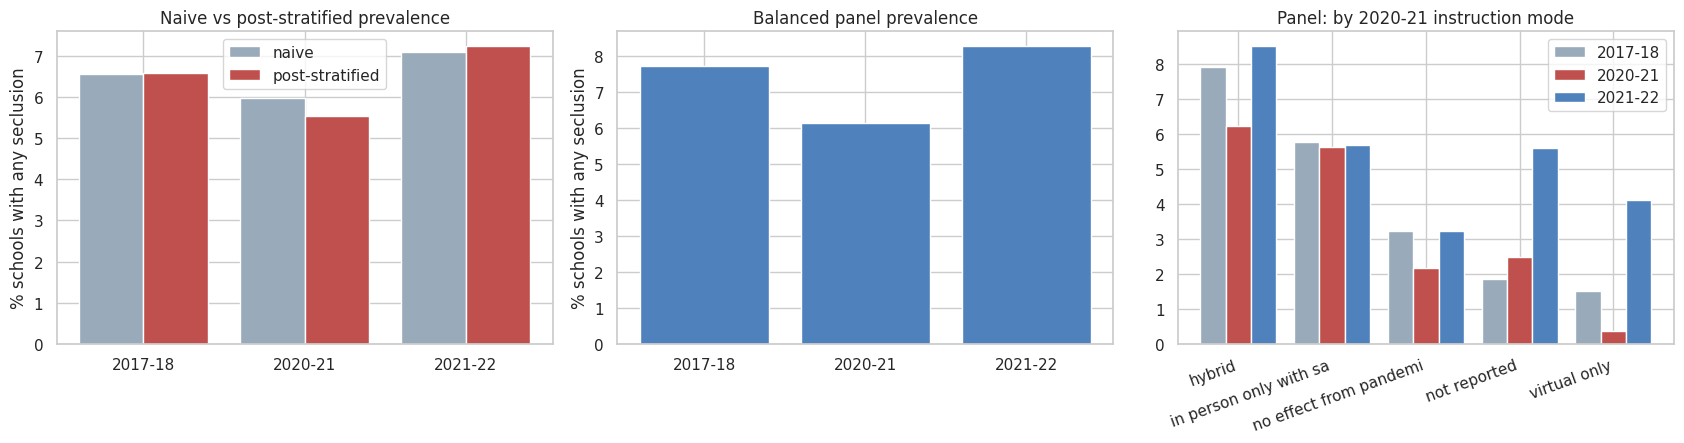

In [30]:
cols_ = ['combokey','lea_state','seclusion_instances','enrollment_total','seclusion_rate']
n18 = pd.read_csv(DATA_DIR/'schools_201718_analysis.csv', usecols=cols_, dtype={'combokey': str, 'lea_state': str})
n22 = pd.read_csv(DATA_DIR/'schools_202122_analysis.csv', usecols=cols_, dtype={'combokey': str, 'lea_state': str})
d20 = df[cols_ + ['covid_mode']] if 'covid_mode' in df else df[cols_ + ['covid_instruction_type']].rename(columns={'covid_instruction_type': 'covid_mode'})
d20 = d20.assign(covid_mode=d20.covid_mode.fillna('not reported'))
waves = {'2017-18': n18, '2020-21': d20, '2021-22': n22}
for k, w in waves.items(): w['any'] = (w.seclusion_instances > 0).astype(int)

# (A) naive
A = pd.DataFrame({k: {'schools_with_outcome': len(w), 'pct_any_seclusion': w['any'].mean()*100, 'mean_instances': w.seclusion_instances.mean(), 'states': w.lea_state.nunique()} for k, w in waves.items()}).T
print('(A) Naive prevalence (all analysis-ready schools in each wave)'); print(A.round(2).to_string())

# (B) selection: share of roster with a valid outcome by state in 2020-21 vs the state's 2017-18 prevalence
roster = full.groupby('lea_state').size().rename('roster20'); valid20 = d20.groupby('lea_state').size().rename('valid20')
p18 = n18.groupby('lea_state')['any'].mean().rename('p18')*100; p22 = n22.groupby('lea_state')['any'].mean().rename('p22')*100; p20 = d20.groupby('lea_state')['any'].mean().rename('p20')*100
S = pd.concat([roster, valid20, p18, p20, p22], axis=1).fillna({'valid20': 0}); S['valid_share20'] = S.valid20/S.roster20
print(f"\n(B) State-level correlation between share of schools with a valid 2020-21 outcome and the state's 2017-18 prevalence: Spearman {S[['valid_share20','p18']].corr(method='spearman').iloc[0,1]:.2f}")
print(f"    Low-validity states (<60% valid) average 2017-18 prevalence {S.loc[S.valid_share20<.6,'p18'].mean():.1f}% vs {S.loc[S.valid_share20>=.9,'p18'].mean():.1f}% for states with >=90% valid")
print('    States below 60% valid:', S.loc[S.valid_share20<.6].assign(v=lambda x:(x.valid_share20*100).round(0)).v.to_dict())

# (C) post-stratify every wave to the 2020-21 roster state mix (states with >= 50 valid schools in all waves)
ok_states = S.index[(S.valid20 >= 50) & S.p18.notna() & S.p22.notna() & (valid20.reindex(S.index) >= 50)]
w_ = roster.loc[ok_states]/roster.loc[ok_states].sum()
C_ = pd.Series({'2017-18': (S.loc[ok_states,'p18']*w_).sum(), '2020-21': (S.loc[ok_states,'p20']*w_).sum(), '2021-22': (S.loc[ok_states,'p22']*w_).sum()})
print(f"\n(C) Prevalence post-stratified to the 2020-21 roster state mix ({len(ok_states)} states): " + ', '.join(f'{k} {v:.2f}%' for k, v in C_.items()))
hi = S.index[S.valid_share20 >= .9]
Chi = pd.Series({k: w.loc[w.lea_state.isin(hi),'any'].mean()*100 for k, w in waves.items()})
print(f"    Only states with >=90% valid outcomes in 2020-21 ({len(hi)} states): " + ', '.join(f'{k} {v:.2f}%' for k, v in Chi.items()))

# (D) balanced panel: same schools in all three waves
P = d20.merge(n18, on='combokey', suffixes=('_20','_18')).merge(n22.rename(columns={c: c+'_22' for c in n22.columns if c != 'combokey'}), on='combokey')
print(f"\n(D) Balanced panel (valid in all three waves): {len(P):,} schools")
D = pd.DataFrame({k: {'pct_any': P[f'any{s}'].mean()*100, 'mean_instances': P[f'seclusion_instances{s}'].mean(), 'pct_elevated(enr>=30)': np.nan} for k, s in [('2017-18','_18'),('2020-21','_20'),('2021-22','_22')]}).T
pe = P[(P.enrollment_total_18>=30)&(P.enrollment_total_20>=30)&(P.enrollment_total_22>=30)]
for k, s in [('2017-18','_18'),('2020-21','_20'),('2021-22','_22')]: D.loc[k,'pct_elevated(enr>=30)'] = ((pe[f'seclusion_instances{s}']>=5)&(pe[f'seclusion_rate{s}']>=1)).mean()*100
print(D.round(2).to_string())
print(f"    Total instances in the panel: 2017-18 {P.seclusion_instances_18.sum():,.0f} | 2020-21 {P.seclusion_instances_20.sum():,.0f} | 2021-22 {P.seclusion_instances_22.sum():,.0f}")
print(f"    P(any 2020-21 | any 2017-18) = {P.loc[P.any_18==1,'any_20'].mean():.1%} | P(any 2020-21 | none 2017-18) = {P.loc[P.any_18==0,'any_20'].mean():.1%} | P(any 2021-22 | any 2020-21) = {P.loc[P.any_20==1,'any_22'].mean():.1%} | P(any 2021-22 | none 2020-21) = {P.loc[P.any_20==0,'any_22'].mean():.1%}")
print(f"    P(any 2020-21 | positive in BOTH 2017-18 and 2021-22) = {P.loc[(P.any_18==1)&(P.any_22==1),'any_20'].mean():.1%}  (schools in the panel positive in both bookends: {int(((P.any_18==1)&(P.any_22==1)).sum()):,})")
bymode = P.groupby('covid_mode').agg(schools=('combokey','size'), any_2017_18=('any_18','mean'), any_2020_21=('any_20','mean'), any_2021_22=('any_22','mean'))
bymode[['any_2017_18','any_2020_21','any_2021_22']] *= 100; bymode['change_2018_to_2021_pts'] = bymode.any_2020_21 - bymode.any_2017_18
fig, ax = plt.subplots(1, 3, figsize=(17, 4.6)); lab = ['2017-18','2020-21','2021-22']
for a_, (t_, vals) in zip(ax[:2], [('Naive vs post-stratified prevalence', None), ('Balanced panel prevalence', D.pct_any.values)]):
    if vals is None:
        w_i = np.arange(3); a_.bar(w_i-.2, A.pct_any_seclusion.values, .4, label='naive', color='#9ab'); a_.bar(w_i+.2, C_.values, .4, label='post-stratified', color='#c0504d'); a_.set_xticks(w_i); a_.set_xticklabels(lab); a_.legend()
    else: a_.bar(lab, vals, color='#4f81bd')
    a_.set_title(t_); a_.set_ylabel('% schools with any seclusion')
bm = bymode[bymode.schools >= 100]; xi = np.arange(len(bm)); ax[2].bar(xi-.27, bm.any_2017_18, .27, label='2017-18', color='#9ab'); ax[2].bar(xi, bm.any_2020_21, .27, label='2020-21', color='#c0504d'); ax[2].bar(xi+.27, bm.any_2021_22, .27, label='2021-22', color='#4f81bd')
ax[2].set_xticks(xi); ax[2].set_xticklabels([m.replace('_',' ')[:22] for m in bm.index], rotation=20, ha='right'); ax[2].legend(); ax[2].set_title('Panel: by 2020-21 instruction mode'); plt.tight_layout()
bymode.round(2)

## 11. Equity patterns (checklist 11, descriptive only)
This file has **students secluded** (unique students) by sex and IDEA status, and instance counts by IDEA / 504 / no-disability. **Race is not in the cleaned file**; the 2020-21 raw CRDC has race columns, so they must be carried through cleaning to complete this item.

Schools with all counts valid: 75,511 of 76,082 (the rest have suppressed IDEA counts or missing seclusion)

All schools
                secluded_students  enrolled_students  secluded_per_100_students  share_of_secluded_%  share_of_enrolled_%  ratio_vs_no_IDEA_female
IDEA male               9,876.000      3,426,770.000                      0.288               63.287                9.085                   52.027
IDEA female             1,859.000      1,804,948.000                      0.103               11.913                4.785                   18.593
No IDEA male            2,953.000     15,932,922.000                      0.019               18.923               42.242                    3.346
No IDEA female            917.000     16,554,005.000                      0.006                5.876               43.888                    1.000

Regular schools only (not sped / alt / justice)
                secluded_students  enrolled_students  secluded_per_100_students  share_of_seclu

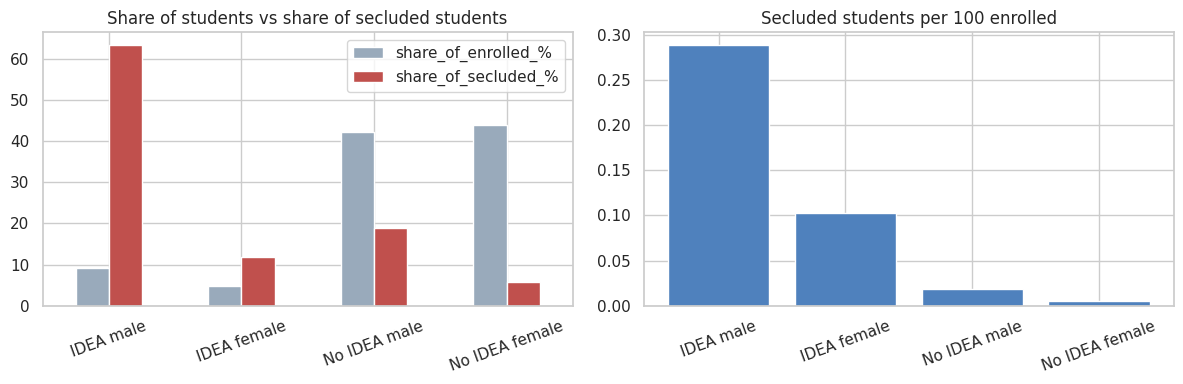

In [31]:
r = raw.loc[df.index]
eq = pd.DataFrame({'tot_m': r.TOT_ENR_M, 'tot_f': r.TOT_ENR_F, 'idea_m': r.SCH_ENR_IDEA_M, 'idea_f': r.SCH_ENR_IDEA_F,
                   'sec_idea_m': r.TOT_RS_IDEA_SECL_M, 'sec_idea_f': r.TOT_RS_IDEA_SECL_F, 'sec_non_m': r.TOT_RS_NONIDEA_SECL_M, 'sec_non_f': r.TOT_RS_NONIDEA_SECL_F,
                   'inst_idea': r.SCH_RSINSTANCES_SECL_IDEA, 'inst_wodis': r.SCH_RSINSTANCES_SECL_WODIS, 'inst_504': r.SCH_RSINSTANCES_SECL_504,
                   'regular': df.regular}).dropna(subset=['tot_m','tot_f','idea_m','idea_f','sec_idea_m','sec_idea_f','sec_non_m','sec_non_f'])
eq['non_m'] = (eq.tot_m - eq.idea_m).clip(lower=0); eq['non_f'] = (eq.tot_f - eq.idea_f).clip(lower=0)
def tbl(d):
    t = pd.DataFrame({'secluded_students': [d.sec_idea_m.sum(), d.sec_idea_f.sum(), d.sec_non_m.sum(), d.sec_non_f.sum()],
                      'enrolled_students': [d.idea_m.sum(), d.idea_f.sum(), d.non_m.sum(), d.non_f.sum()]}, index=['IDEA male','IDEA female','No IDEA male','No IDEA female'])
    t['secluded_per_100_students'] = t.secluded_students/t.enrolled_students*100
    t['share_of_secluded_%'] = t.secluded_students/t.secluded_students.sum()*100; t['share_of_enrolled_%'] = t.enrolled_students/t.enrolled_students.sum()*100
    t['ratio_vs_no_IDEA_female'] = t.secluded_per_100_students/t.loc['No IDEA female','secluded_per_100_students']; return t
print(f'Schools with all counts valid: {len(eq):,} of {len(df):,} (the rest have suppressed IDEA counts or missing seclusion)')
print('\nAll schools'); eqt = tbl(eq); print(eqt.round(3).to_string())
print('\nRegular schools only (not sped / alt / justice)'); print(tbl(eq[eq.regular]).round(3).to_string())
idea_all = eq.sec_idea_m.sum()+eq.sec_idea_f.sum(); non_all = eq.sec_non_m.sum()+eq.sec_non_f.sum()
print(f"\nIDEA vs no-IDEA: {idea_all/(eq.idea_m.sum()+eq.idea_f.sum())*100:.2f} vs {non_all/(eq.non_m.sum()+eq.non_f.sum())*100:.3f} secluded students per 100 -> ratio {(idea_all/(eq.idea_m.sum()+eq.idea_f.sum()))/(non_all/(eq.non_m.sum()+eq.non_f.sum())):.1f}x")
print(f"Male vs female (all students): {(eq.sec_idea_m.sum()+eq.sec_non_m.sum())/(eq.idea_m.sum()+eq.non_m.sum())*100:.3f} vs {(eq.sec_idea_f.sum()+eq.sec_non_f.sum())/(eq.idea_f.sum()+eq.non_f.sum())*100:.3f} per 100; male share of secluded students {(eq.sec_idea_m.sum()+eq.sec_non_m.sum())/(idea_all+non_all):.1%}")
print(f"Instances per secluded student: IDEA {eq.inst_idea.sum()/idea_all:.2f} | no-IDEA (WODIS+504) {(eq.inst_wodis.sum()+eq.inst_504.sum())/non_all:.2f}  (repeated seclusion of the same students)")
fig, ax = plt.subplots(1, 2, figsize=(12, 4)); eqt[['share_of_enrolled_%','share_of_secluded_%']].plot.bar(ax=ax[0], color=['#9ab','#c0504d']); ax[0].set_title('Share of students vs share of secluded students'); ax[0].tick_params(axis='x', rotation=20)
ax[1].bar(eqt.index, eqt.secluded_per_100_students, color='#4f81bd'); ax[1].set_title('Secluded students per 100 enrolled'); ax[1].tick_params(axis='x', rotation=20); plt.tight_layout()

## 12. Correlations among candidate features (checklist 12)

,,rho
log_lea_enrollment,log_lea_schools,0.960
log_enrollment,fte_teachers,0.900
counselors_p100,fte_counselors,0.680
fte_teachers,fte_counselors,0.610
log_enrollment,fte_counselors,0.570


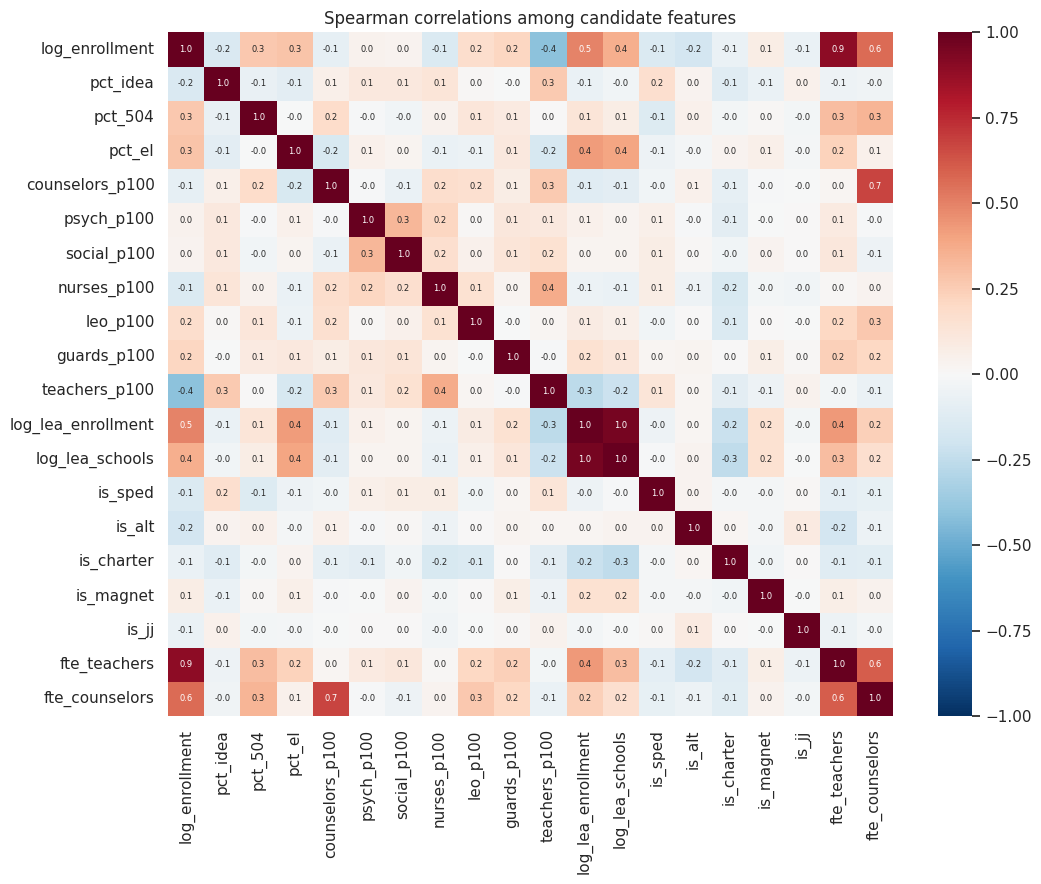

In [32]:
cand = df[df.enr_ge30 & ~df.flag_fte_outlier].copy()
cand['log_enrollment'] = np.log(cand.enrollment_total); cand['log_lea_enrollment'] = np.log(cand.lea_enrollment.clip(lower=1)); cand['log_lea_schools'] = np.log1p(cand.lea_schools)
for c in ['counselors','psych','social','nurses','leo','guards','teachers']:
    cand[f'{c}_p100'] = (cand[f'fte_{c}']/cand.enrollment_total*100); cand[f'{c}_p100'] = cand[f'{c}_p100'].clip(upper=cand[f'{c}_p100'].quantile(.995))
for c in ['sped','alt','charter','magnet','jj']: cand[f'is_{c}'] = cand[f'type_{c}'].astype(int)
feats = ['log_enrollment','pct_idea','pct_504','pct_el','counselors_p100','psych_p100','social_p100','nurses_p100','leo_p100','guards_p100','teachers_p100',
         'log_lea_enrollment','log_lea_schools','is_sped','is_alt','is_charter','is_magnet','is_jj','fte_teachers','fte_counselors']
corr = cand[feats].corr(method='spearman')
fig, ax = plt.subplots(figsize=(11, 9)); sns.heatmap(corr, cmap='RdBu_r', center=0, vmin=-1, vmax=1, annot=True, fmt='.1f', annot_kws={'size':6}, ax=ax); ax.set_title('Spearman correlations among candidate features'); plt.tight_layout()
pairs = corr.where(np.triu(np.ones(corr.shape), 1).astype(bool)).stack().rename('rho'); pairs = pairs[pairs.abs()>=.5].sort_values(key=abs, ascending=False)
pairs.round(2)

## 13. Leakage review (checklist 13)
2015-16 includes the mechanical and physical restraint counts, so the restraint leakage risk can be measured directly.

In [33]:
from sklearn.metrics import roc_auc_score
r = raw.loc[df.index]
df['phys_inst'] = r[['SCH_RSINSTANCES_PHYS_WODIS','SCH_RSINSTANCES_PHYS_IDEA','SCH_RSINSTANCES_PHYS_504']].sum(axis=1, min_count=3)
df['mech_inst'] = r[['SCH_RSINSTANCES_MECH_WODIS','SCH_RSINSTANCES_MECH_IDEA','SCH_RSINSTANCES_MECH_504']].sum(axis=1, min_count=3)
rows = []
for nm, col in [('physical restraint instances','phys_inst'), ('mechanical restraint instances','mech_inst')]:
    d = df.dropna(subset=[col]); anyr = d[col] > 0
    rows.append({'measure': nm, 'schools_with_valid_value': len(d), 'schools_with_any_restraint_%': anyr.mean()*100,
                 'pct_any_secl | restraint>0': d.loc[anyr,'any_secl'].mean()*100, 'pct_any_secl | restraint=0': d.loc[~anyr,'any_secl'].mean()*100,
                 'spearman_with_secl_instances': d[[col,'seclusion_instances']].corr(method='spearman').iloc[0,1], 'AUC_alone_for_any_secl': roc_auc_score(d.any_secl, d[col])})
d = df.dropna(subset=['phys_inst','mech_inst']); d_ = d.assign(rs=d.phys_inst + d.mech_inst)
rows.append({'measure': 'physical + mechanical', 'schools_with_valid_value': len(d_), 'schools_with_any_restraint_%': (d_.rs>0).mean()*100,
             'pct_any_secl | restraint>0': d_.loc[d_.rs>0,'any_secl'].mean()*100, 'pct_any_secl | restraint=0': d_.loc[d_.rs==0,'any_secl'].mean()*100,
             'spearman_with_secl_instances': d_[['rs','seclusion_instances']].corr(method='spearman').iloc[0,1], 'AUC_alone_for_any_secl': roc_auc_score(d_.any_secl, d_.rs)})
print('Compare with the full non-leaking feature set F in section 14.')
pd.DataFrame(rows).set_index('measure').round(3)

Compare with the full non-leaking feature set F in section 14.

,schools_with_valid_value,schools_with_any_restraint_%,pct_any_secl | restraint>0,pct_any_secl | restraint=0,spearman_with_secl_instances,AUC_alone_for_any_secl
measure,,,,,,
physical restraint instances,76051,16.801,26.931,1.724,0.417,0.829
mechanical restraint instances,76080,0.789,22.333,5.840,0.062,0.512
physical + mechanical,76049,17.138,26.571,1.696,0.416,0.831


In [34]:
leak = pd.DataFrame([
 ('SCH_RSINSTANCES_SECL_WODIS / _IDEA / _504 (seclusion_instances_*)', 'DIRECT LEAK', 'Components of the outcome (instances = their sum).'),
 ('seclusion_instances, seclusion_rate_per_100, seclusion_reason*',    'DIRECT LEAK', 'The outcome, its transform, or its missingness reason.'),
 ('TOT_RS_IDEA_SECL_M/F, TOT_RS_NONIDEA_SECL_M/F, secl_students_*_n',  'DIRECT LEAK', 'Number of students secluded (same event, different count). Equity analysis only.'),
 ('SCH_RSINSTANCES_PHYS_* , SCH_RSINSTANCES_MECH_* (restraint)',        'LEAK RISK - exclude', 'Reported in the same CRDC section as seclusion and strongly co-occur (see table above and the AUC jump in section 14).'),
 ('Other discipline (suspensions, expulsions, referrals, arrests)',    'Not in file', 'Not carried through cleaning; same behavioural events. Keep out of the baseline model if added later.'),
 ('fte_leo, fte_guards (security)',                                      'Reverse-causality risk', 'Schools with behaviour problems may hire security. fte_leo is 5.7% missing in 2020-21.'),
 ('flag_missing_seclusion, flag_rate_undefined, *_code, *_reason',       'Exclude', 'Define the sample / describe the outcome; constant in the analysis-ready subset.'),
 ('LEAID, SCHID, COMBOKEY, COMBOKEY_stored, names',                      'Identifier', 'Not features. Use leaid for grouped cross-validation only.'),
], columns=['variable','status','why'])
print(leak.to_string(index=False))
cand_ = cand.copy(); cand_['phys_p100_'] = (df.loc[cand.index,'phys_inst']/cand.enrollment_total*100)
print('\nAbsolute Spearman with any_secl, strongest first (enr>=30, no outliers):')
cc = cand_[feats+['seclusion_instances_idea','seclusion_instances_wodis','seclusion_instances_504','phys_p100_','any_secl']].corr(method='spearman')['any_secl'].drop('any_secl').abs().sort_values(ascending=False); print(cc.round(3).head(12).to_string())

                                                         variable                 status                                                                                                                    why
SCH_RSINSTANCES_SECL_WODIS / _IDEA / _504 (seclusion_instances_*)            DIRECT LEAK                                                                     Components of the outcome (instances = their sum).
   seclusion_instances, seclusion_rate_per_100, seclusion_reason*            DIRECT LEAK                                                                 The outcome, its transform, or its missingness reason.
 TOT_RS_IDEA_SECL_M/F, TOT_RS_NONIDEA_SECL_M/F, secl_students_*_n            DIRECT LEAK                                       Number of students secluded (same event, different count). Equity analysis only.
      SCH_RSINSTANCES_PHYS_* , SCH_RSINSTANCES_MECH_* (restraint)    LEAK RISK - exclude Reported in the same CRDC section as seclusion and strongly co-occur (see table

## 14. Baseline signal check: which feature groups carry information?
Grouped (by district) 5-fold cross-validation so schools of the same district never straddle train/test. Metric: ROC-AUC and average precision (the positive class is only ~6.6%, so AP matters). This is a signal check to inform the shortlist, not a final model.

In [35]:
from sklearn.model_selection import GroupKFold, cross_val_predict
from sklearn.metrics import roc_auc_score, average_precision_score
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
mdl = cand.dropna(subset=['pct_504','pct_el']).copy()
mdl['idea_suppressed'] = mdl.pct_idea.isna().astype(int)   # keep rows with missing %IDEA (under 1%), add indicator
for c in ['fte_leo','fte_guards']: pass
mdl = pd.concat([mdl, pd.get_dummies(mdl.grade_band, prefix='gb', dtype=float)], axis=1)
gb_cols = [c for c in mdl.columns if c.startswith('gb_')]
size = ['log_enrollment']; typ = ['is_sped','is_alt','is_charter','is_magnet','is_jj']+gb_cols
pop = ['pct_idea','pct_504','pct_el','idea_suppressed']; staffc = ['counselors_p100','psych_p100','social_p100','nurses_p100','teachers_p100']; sec = ['leo_p100','guards_p100']
lea = ['log_lea_enrollment','log_lea_schools']
mdl = pd.concat([mdl, pd.get_dummies(mdl.lea_state, prefix='st', dtype=float)], axis=1); st_cols = [c for c in mdl.columns if c.startswith('st_')]
sets = {'A size only': size, 'B + type & grade': size+typ, 'C + population shares': size+typ+pop, 'D + staffing': size+typ+pop+staffc,
        'E + security staff': size+typ+pop+staffc+sec, 'F + district size': size+typ+pop+staffc+sec+lea, 'G + state (one-hot)': size+typ+pop+staffc+sec+lea+st_cols}
y = mdl.any_secl.values; groups = mdl.leaid.values; res = []
for name, cols_ in sets.items():
    pipe = make_pipeline(SimpleImputer(strategy='median'), HistGradientBoostingClassifier(max_iter=150, learning_rate=.08, max_depth=4, random_state=0))
    p = cross_val_predict(pipe, mdl[cols_], y, cv=GroupKFold(5), groups=groups, method='predict_proba')[:,1]
    res.append({'feature set': name, 'n_features': len(cols_), 'ROC_AUC': roc_auc_score(y, p), 'avg_precision': average_precision_score(y, p)})
base = pd.DataFrame(res).set_index('feature set'); print(f'rows={len(mdl):,}; positive rate={y.mean():.3%} (AP baseline = positive rate)'); base.round(3)

rows=72,248; positive rate=6.056% (AP baseline = positive rate)

,n_features,ROC_AUC,avg_precision
feature set,,,
A size only,1,0.552,0.068
B + type & grade,11,0.664,0.108
C + population shares,15,0.699,0.126
D + staffing,20,0.727,0.157
E + security staff,22,0.729,0.161
F + district size,24,0.732,0.156
G + state (one-hot),74,0.833,0.316


In [36]:
# Permutation importance (AUC drop) for the F model on a held-out grouped split
from sklearn.model_selection import GroupShuffleSplit
from sklearn.inspection import permutation_importance
cols_ = sets['F + district size']; tr, te = next(GroupShuffleSplit(1, test_size=.25, random_state=1).split(mdl, y, groups))
pipe = make_pipeline(SimpleImputer(strategy='median'), HistGradientBoostingClassifier(max_iter=150, learning_rate=.08, max_depth=4, random_state=0)).fit(mdl.iloc[tr][cols_], y[tr])
pi = permutation_importance(pipe, mdl.iloc[te][cols_], y[te], scoring='roc_auc', n_repeats=5, random_state=0)
imp = pd.Series(pi.importances_mean, index=cols_).sort_values(ascending=False); print('held-out AUC:', round(roc_auc_score(y[te], pipe.predict_proba(mdl.iloc[te][cols_])[:,1]),3)); imp.round(4)

held-out AUC: 0.719

,0
pct_504,0.035
teachers_p100,0.029
pct_idea,0.028
log_lea_enrollment,0.024
gb_high,0.024
log_enrollment,0.021
gb_elementary,0.017
pct_el,0.015
guards_p100,0.012
log_lea_schools,0.009


In [37]:
# Leakage demonstration: add restraint counts to the F feature set (NOT recommended - shows how much signal they leak)
mdl['phys_p100'] = (df.loc[mdl.index,'phys_inst']/mdl.enrollment_total*100).clip(upper=100); mdl['mech_p100'] = (df.loc[mdl.index,'mech_inst']/mdl.enrollment_total*100).clip(upper=100)
cols_ = sets['F + district size'] + ['phys_p100','mech_p100']
pipe = make_pipeline(SimpleImputer(strategy='median'), HistGradientBoostingClassifier(max_iter=150, learning_rate=.08, max_depth=4, random_state=0))
p = cross_val_predict(pipe, mdl[cols_], y, cv=GroupKFold(5), groups=groups, method='predict_proba')[:,1]
print(f"F + restraint: ROC-AUC {roc_auc_score(y, p):.3f}, average precision {average_precision_score(y, p):.3f}   (F alone: {base.loc['F + district size','ROC_AUC']:.3f} / {base.loc['F + district size','avg_precision']:.3f})")

F + restraint: ROC-AUC 0.872, average precision 0.432   (F alone: 0.732 / 0.156)

## 15. Data issues found during EDA (checklist deliverable 4)

In [38]:
issues = []
def add(i, sev, issue, n, detail): issues.append({'#': i, 'severity': sev, 'issue': issue, 'rows': n, 'detail': detail})
reg_ = df[df.regular]
no_flag = int(raw.flag_rate_undefined.sum()); sup_n = int(raw.seclusion_reason.eq('suppressed').sum())
add(1,'High','22% of schools have no usable outcome; -11 data-quality suppression is not random', no_flag, f'{no_flag:,} of 97,575 rows ({no_flag/len(raw):.1%}) have an undefined rate; {sup_n:,} ({sup_n/len(raw):.1%}) are -11 (suppressed) and are concentrated by state (Hawaii 100%, Florida 54%, Nevada 51%, North Carolina 42%, Maryland 38%, New York 36%...). Those states report little seclusion in other years, so the analysis sample over-represents high-reporting states. Document this prominently and provide state-level validity weights.')
add(2,'High','Virtual-only schools skipped the module (-13)', int(raw.flag_virtual_only_skip.sum()), f'{int(raw.flag_virtual_only_skip.sum()):,} schools ({raw.loc[raw.flag_virtual_only_skip,"flag_covid_virtual_only"].mean():.0%} of them virtual-only by the COVID indicator); 90.7% of all virtual-only schools skipped the module and only {int(((raw.covid_instruction_type=="virtual_only") & raw.seclusion_instances.notna()).sum())} of {int(raw.flag_covid_virtual_only.sum()):,} virtual-only schools have a valid outcome. Virtual vs in-person seclusion cannot be compared fairly.')
add(3,'High','File named "analysis_ready" is not filtered and has no readiness flag', len(raw), 'All 97,575 rows are kept (including the 21,493 with an undefined rate). Add a flag_analysis_ready like the 2017-18 and 2021-22 files, and drop or flag small and FTE-outlier rows consistently.')
add(4,'Med','Implausible FTE values retained', int(raw.flag_fte_outlier.sum()), f'flag_fte_outlier fires on {int(raw.flag_fte_outlier.sum())} schools but they stay in the file; max nurse FTE {raw.SCH_FTESERVICES_NUR.max():,.0f}, max counselor FTE {raw.SCH_FTECOUNSELORS.max():,.0f}. Security FTE is -9 for 573 of 579 justice facilities (audit), so security ratios are biased for those schools.')
add(5,'Med','Extreme seclusion counts', int((df.seclusion_instances > df.enrollment_total).sum()), f'{int((df.seclusion_instances > df.enrollment_total).sum())} analysis-ready rows have more instances than students; {int((reg_.seclusion_rate>25).sum())} regular schools exceed 25 per 100; max {df.seclusion_instances.max():,.0f} instances (West Kearney High School, NE: 1,714 instances / 109 students). Verify against CRDC before using as labels.')
add(6,'Med','COVID indicators have limited resolution', int(raw.flag_dind_missing.sum()), f'{raw.covid_instruction_type.eq("hybrid").mean():.0%} of schools are coded hybrid, 247 have no instruction type and {int(raw.covid_virtual_type.isna().sum()):,} no virtual type ({int(raw.flag_dind_virtual_skip.sum()):,} are -13 skips). A single self-reported category cannot separate months of remote vs in-person learning.')
add(7,'Med','Enrollment missing (-11) for some schools', int(raw.flag_missing_enrollment.sum()), f'{int(raw.flag_missing_enrollment.sum())} schools have no usable enrollment (561 / 560 suppressed for M / F); rates and per-100 ratios are undefined for them.')
add(8,'Med','Schema differs from the 2017-18 and 2021-22 files', len(raw.columns), '176 columns (about 100 are *_code / *_reason helpers), upper-case source names, and renamed derived fields (enrollment vs enrollment_total, seclusion_rate_per_100 vs seclusion_rate, idea_share as a 0-1 fraction vs pct_idea in 0-100). Publish one harmonised schema before pooling years.')
add(9,'Med','Small-enrollment flag and grade_band inconsistent across years', int(raw.flag_small_enrollment.sum()), 'flag_small_enrollment is enrollment < 50 here (5,702 schools) but < 10 in 2017-18 and 2021-22; neither is the right cut-off for rates (this EDA recommends 30). grade_band is not provided; derived here from SCH_GRADE_* flags.')
add(10,'Med','Race of secluded students and other discipline measures not carried through', 0, 'Required for the race equity item; physical and mechanical restraint are present (and must be excluded as leakage) but suspensions, expulsions and referrals are absent.')
add(11,'Low','COMBOKEY_stored left in the output', len(raw), 'The pre-rebuild key is kept beside the rebuilt one (no scientific-notation corruption in 2020-21). Drop it or rename it to avoid accidental joins.')
add(12,'Low','seclusion_rate_per_100 naming and units', len(df), 'Instances per 100 students (can exceed 100); keep one name across years.')
add(13,'Low','Law-enforcement and guard FTE missing', int(raw.SCH_FTESECURITY_LEO.isna().sum()), f'{raw.SCH_FTESECURITY_LEO.isna().mean():.1%} missing (-9); decide on imputing 0 vs NA, especially for justice facilities.')
pd.DataFrame(issues).set_index('#')

,severity,issue,rows,detail
#,,,,
1,High,22% of schools have no usable outcome; -11 data-quality suppression is not random,21493,"21,493 of 97,575 rows (22.0%) have an undefined rate; 14,166 (14.5%) are -11 (suppressed) and are concentrated by state (Hawaii 100%, Florida 54%, Nevada 51%, North Carolina 42%, Maryland 38%, New York 36%...). Those states report little seclusion in other years, so the analysis sample over-represents high-reporting states. Document this prominently and provide state-level validity weights."
2,High,Virtual-only schools skipped the module (-13),4700,"4,700 schools (100% of them virtual-only by the COVID indicator); 90.7% of all virtual-only schools skipped the module and only 342 of 5,189 virtual-only schools have a valid outcome. Virtual vs in-person seclusion cannot be compared fairly."
3,High,"File named ""analysis_ready"" is not filtered and has no readiness flag",97575,"All 97,575 rows are kept (including the 21,493 with an undefined rate). Add a flag_analysis_ready like the 2017-18 and 2021-22 files, and drop or flag small and FTE-outlier rows consistently."
4,Med,Implausible FTE values retained,758,"flag_fte_outlier fires on 758 schools but they stay in the file; max nurse FTE 833, max counselor FTE 205. Security FTE is -9 for 573 of 579 justice facilities (audit), so security ratios are biased for those schools."
5,Med,Extreme seclusion counts,82,"82 analysis-ready rows have more instances than students; 76 regular schools exceed 25 per 100; max 1,714 instances (West Kearney High School, NE: 1,714 instances / 109 students). Verify against CRDC before using as labels."
6,Med,COVID indicators have limited resolution,6807,"88% of schools are coded hybrid, 247 have no instruction type and 6,803 no virtual type (6,482 are -13 skips). A single self-reported category cannot separate months of remote vs in-person learning."
7,Med,Enrollment missing (-11) for some schools,592,592 schools have no usable enrollment (561 / 560 suppressed for M / F); rates and per-100 ratios are undefined for them.
8,Med,Schema differs from the 2017-18 and 2021-22 files,176,"176 columns (about 100 are *_code / *_reason helpers), upper-case source names, and renamed derived fields (enrollment vs enrollment_total, seclusion_rate_per_100 vs seclusion_rate, idea_share as a 0-1 fraction vs pct_idea in 0-100). Publish one harmonised schema before pooling years."
9,Med,Small-enrollment flag and grade_band inconsistent across years,5702,"flag_small_enrollment is enrollment < 50 here (5,702 schools) but < 10 in 2017-18 and 2021-22; neither is the right cut-off for rates (this EDA recommends 30). grade_band is not provided; derived here from SCH_GRADE_* flags."


## 16. Key findings (2020-21)
1. **Audit counts match, but 22% of schools have no usable outcome.** All 16 audit counts reproduce exactly. Of 97,575 schools, 76,082 (78.0%) are analysis-ready; 21,493 are not: -11 data-quality suppression 14,166 (14.5%), structural skips 6,575 (of which -13 virtual-only skip 4,700 and -9 1,875) and -5 missing 288. Suppression is **concentrated by state**: Hawaii 100%, Florida 54%, Nevada 51%, North Carolina 42%, Maryland 38%, New York 36%; the 8 biggest states hold 70% of suppressed schools. States with under 60% valid outcomes averaged 2.7% any-seclusion in 2017-18 versus 9.5% for states with 90%+ valid, so the analysis sample over-represents high-reporting states. The cleaning script itself labels 2020-21 a sensitivity cohort, not a primary year.
2. **Seclusion is rare and extremely skewed.** 94.0% of schools report zero; 5.97% (4,542) report at least one instance (5.50% in 2015-16, 6.56% in 2017-18, 7.09% in 2021-22). Among those, the median is 4 instances, the 90th percentile 31 and the maximum 1,714. The top 100 schools hold 32.1% of instances.
3. **State dominates, as in every year.** Iowa 29.3%, Wisconsin 27.8%, Connecticut 25.9%, Maine 22.9%, Nebraska 17.9% report any seclusion; California, Texas, Massachusetts, New York and Louisiana are near or under 1.1%; Nevada's 345 valid schools report none; Hawaii and Puerto Rico have no valid schools. State alone gives ROC-AUC 0.80, and adding it to the baseline lifts average precision from 0.16 to 0.32.
4. **Most concentrated in districts of any year.** 11.3% of districts have any school reporting seclusion; 89 districts hold half of all instances and 355 hold 80%; the top 10 hold 18.0%. Lincoln Public Schools (NE) alone is 4.0%; a single school (West Kearney High School, NE) reports 1,714 instances for 109 students.
5. **School type.** Special-education schools: 20.5% any (vs 5.7%) and 17.9% of instances; justice facilities 9.7% (median rate 144 per 100 when positive); alternative 1.7%, charter 1.5%, magnet 4.7%. Elementary 8.7%, span 5.4%, middle 4.1%, high 2.3%. 93.0% of positive schools are ordinary schools.
6. **COVID instruction mode.** 87.8% of schools are coded hybrid, so the indicator has little resolution. Virtual-only schools (5,189) skipped the module: only 342 have a valid outcome and 0.9% of them report any seclusion. Adjusted for state and size (regular schools, 30+ students), in-person-only schools have odds 0.60 of any seclusion versus hybrid, but the virtual-only and no-effect groups have under 750 schools and the ratios are not reliable.
7. **Student population.** %IDEA is the clearest positive correlate (2.6% any under 5% IDEA, 8.0% at 20-30%, then falling); %504 is the strongest negative (7.8% at 0.5-2%, 1.4% at 10% or more); %EL is inverted-U. All rank correlations with the outcome are weak (|rho| <= 0.08). Missingness of these counts is small in 2020-21 (0.8-2.8%).
8. **Staffing.** Non-monotonic and confounded by school size and need. Psychologists and social workers are positively associated after adjustment; security guards, law-enforcement FTE and nurses negative; counselors near zero. 758 schools carry the cleaning outlier flag and are excluded from staffing analysis.
9. **Small enrollments distort rates.** Schools under 30 students are 3.8% of schools and 4.4% of instances but 43% of schools with rates above 100 per 100. Median rate among positives is 50 for enrollments of 1-9 and 9.9 for 30-99, versus 1.0 for 250-499. Use a minimum of 30 plus shrinkage (k about 30-100).
10. **COVID check (2017-18 vs 2020-21 vs 2021-22).** In the balanced panel of 67,775 schools valid in all three waves, any-seclusion fell from 7.71% (2017-18) to 6.13% (2020-21) and rebounded to 8.27% (2021-22); elevated schools went 3.72% to 2.43% to 3.80%; total instances fell 58% (121,009 to 50,917) and recovered to 89,552. Naive prevalence (6.56% to 5.97% to 7.09%), prevalence post-stratified to the 2020-21 state mix (6.59% to 5.55% to 7.23%) and prevalence in the 20 high-validity states (9.30% to 8.09% to 10.13%) all show the same dip of about one point. Persistence stays high: 38.1% of schools with any in 2017-18 also have any in 2020-21 (3.5% of the others), and 58.3% of 2020-21 positives have any in 2021-22. The dip sits in hybrid schools (7.92% to 6.23% to 8.50%); in-person-only schools were flat (5.77% to 5.63% to 5.68%). This is association only.
11. **Equity (sex and disability).** Boys are 82% of secluded students. Students with IDEA are 13.9% of enrolled students but 75.2% of secluded students: 0.22 secluded students per 100 versus 0.012 for others (19x); IDEA boys 0.288 per 100 versus 0.006 for non-IDEA girls (52x). IDEA students were secluded 4.1 times on average versus 2.0 for others. Race could not be assessed.
12. **Leakage.** The seclusion components, rate and secluded-student counts are the outcome. Physical restraint is a strong leak: 26.9% of schools with physical restraint report seclusion versus 1.7% without (AUC 0.83 alone); adding restraint to the baseline raises ROC-AUC from 0.73 to 0.87 and average precision from 0.16 to 0.43. Mechanical restraint is rare (0.8%) and weak but belongs to the same module. Exclude both.
13. **Redundant features.** District enrollment and district school count (rho 0.96); school enrollment and teacher FTE (0.90); counselors per 100 and counselor FTE (0.68).

## 17. Recommended target definition
| | Definition | Prevalence | Use |
|---|---|---|---|
| **Primary: `any_seclusion`** | `seclusion_instances >= 1` | 6.0% of analysis-ready schools | Main classification target (same as other years). |
| **Secondary: `elevated_seclusion`** | `seclusion_instances >= 5` **and** `seclusion_rate_per_100 >= 1` | 2.4% of schools with enrollment >= 30 | Sensitivity analysis. |
| Not recommended | Raw rate or raw count as regression target | | 94% zeros, heavy tail (max 2,950 per 100), denominator-driven for small schools. |

**Role of 2020-21:** use it as a **sensitivity/robustness year, not as a primary training year and not pooled blindly.** The missing 22% is state-concentrated, so any pooled model needs a state effect (or state validity weights) and a year indicator. **Modeling frame (if used):** `~flag_rate_undefined`, enrollment >= 30 (drops 2,864 schools), exclude `flag_fte_outlier` rows, grouped cross-validation by `LEAID`; exclude or separately report virtual-only schools. For the cross-year question, prefer the balanced-panel comparison used in section 10.

In [39]:
shortlist = pd.DataFrame([
 ('log(enrollment)', 'Size', 'Include', 'Scale effect; instances scale with students.'),
 ('grade_band (derived)', 'School type', 'Include', 'Elementary 8.7% vs high 2.3% any seclusion; holds in regular schools. Needs a documented upstream rule.'),
 ('flag_sped', 'School type', 'Include', '20.5% vs 5.7% any; 17.9% of instances.'),
 ('flag_alt', 'School type', 'Include', 'Lower rate, distinct population.'),
 ('flag_charter', 'School type', 'Include', '1.5% vs 6.3% any.'),
 ('flag_jj', 'School type', 'Include', 'Small group (579) but extreme counts when positive.'),
 ('flag_magnet', 'School type', 'Optional', 'Weak permutation importance.'),
 ('idea_share (pct_idea)', 'Population', 'Include', 'Clearest positive correlate; only 1.2% missing.'),
 ('sec504_share (pct_504)', 'Population', 'Include', 'Strongest negative correlate and top permutation importance.'),
 ('lep_share (pct_el)', 'Population', 'Include', 'Inverted-U; weak but independent of IDEA.'),
 ('psych per 100, social per 100', 'Staffing', 'Include', 'Positive association after adjustment; cap per-100 ratios at the 99.5th percentile.'),
 ('counselors per 100, nurses per 100, teachers per 100', 'Staffing', 'Optional', 'Small adjusted effects; teachers per 100 is unstable for tiny schools.'),
 ('fte_leo / fte_guards per 100', 'Security', 'Optional (caution)', 'Negative association; likely reverse causality; 5.7% missing, and -9 for 573 of 579 justice facilities.'),
 ('log(LEA_ENR)', 'District context', 'Include', 'Useful district-size signal; drop LEA_SCHOOLS (rho 0.96).'),
 ('covid_instruction_type', 'COVID', 'Optional (2020-21 only)', '87.8% hybrid; virtual-only has almost no valid outcomes; not available in other years.'),
 ('LEA_STATE (categorical / region)', 'Context', 'Include in a second model', 'Dominant signal (AUC 0.73 -> 0.83); reflects state law, reporting and 2020-21 suppression. Run with and without.'),
 ('SCH_FTETEACH_TOT, SCH_FTECOUNSELORS (raw counts)', 'Staffing', 'Drop', 'Redundant with enrollment (rho 0.90 / 0.57).'),
 ('LEA_SCHOOLS', 'District context', 'Drop', 'rho 0.96 with log(LEA_ENR).'),
 ('SCH_RSINSTANCES_SECL_*, seclusion_instances, seclusion_rate_per_100, TOT_RS_*_SECL_*, secl_students_*', 'Outcome', 'EXCLUDE (leak)', 'Components or transforms of the target.'),
 ('SCH_RSINSTANCES_PHYS_*, SCH_RSINSTANCES_MECH_*', 'Restraint', 'EXCLUDE (leak)', 'Measured: AUC 0.83 alone; raises baseline AUC from 0.73 to 0.87.'),
 ('COMBOKEY_stored, *_code, *_reason, flag_missing_*, flag_virtual_only_skip, flag_dind_*', 'Helper', 'Not features', 'Key bookkeeping and reserved-code descriptors (some encode the outcome status).'),
 ('LEAID, SCHID, COMBOKEY, names', 'Identifier', 'Not features', 'Use LEAID for grouped CV only.'),
], columns=['feature','group','decision','reason'])
shortlist

,feature,group,decision,reason
0,log(enrollment),Size,Include,Scale effect; instances scale with students.
1,grade_band (derived),School type,Include,Elementary 8.7% vs high 2.3% any seclusion; holds in regular schools. Needs a documented upstream rule.
2,flag_sped,School type,Include,20.5% vs 5.7% any; 17.9% of instances.
3,flag_alt,School type,Include,"Lower rate, distinct population."
4,flag_charter,School type,Include,1.5% vs 6.3% any.
5,flag_jj,School type,Include,Small group (579) but extreme counts when positive.
6,flag_magnet,School type,Optional,Weak permutation importance.
7,idea_share (pct_idea),Population,Include,Clearest positive correlate; only 1.2% missing.
8,sec504_share (pct_504),Population,Include,Strongest negative correlate and top permutation importance.
9,lep_share (pct_el),Population,Include,Inverted-U; weak but independent of IDEA.


In [40]:
OUT_DIR = Path('/mnt/user-data/outputs'); OUT_DIR.mkdir(parents=True, exist_ok=True)
shortlist.to_csv(OUT_DIR/'feature_shortlist_202021.csv', index=False)
pd.DataFrame(issues).to_csv(OUT_DIR/'data_issues_202021.csv', index=False)
frame = df[(df.enrollment_total >= 30) & ~df.flag_fte_outlier].copy()
frame['elevated_seclusion'] = ((frame.seclusion_instances >= 5) & (frame.seclusion_rate >= 1)).astype(int)
print(f"Modeling frame: {len(frame):,} schools | any_seclusion prevalence {frame.any_secl.mean():.2%} | elevated_seclusion prevalence {frame.elevated_seclusion.mean():.2%} ({frame.elevated_seclusion.sum():,} schools)")
print('Schools under 30 students dropped:', int((df.enrollment_total < 30).sum()))

Modeling frame: 73,130 schools | any_seclusion prevalence 6.08% | elevated_seclusion prevalence 2.40% (1,756 schools)
Schools under 30 students dropped: 2864